# Error profile checks: changes with a known cause

The error profile explains why a frozen mortality predictor's errors change from one year to the next, one level at a time: what moved; an overall shift of all scores; record length; features; concepts. It has never been checked as a method. Here we make changes whose cause we know to the evaluation patients of the year after each predictor's reference year, and look at what the profile reports at every level. Predictors: reference years 2010–2013. No model is run; everything uses scores that were already saved.

**Terms used throughout (each defined once).**
- *Flagged*: the predictor's score is at or above its frozen threshold.
- *False alarm*: a survivor who is flagged. *False-alarm rate*: false alarms among survivors.
- *Missed death*: a patient who died and was not flagged. *Recall*: deaths that were flagged, among all deaths.
- *Months with care*: the number of months in the year with at least one recorded care event (0–12); the record-length level groups patients by it.
- *Mix / within*: a change in an error rate split exactly into two parts. *Mix* is the part due to patients moving between record-length groups (or into and out of a rule); *within* is the part due to error rates changing inside groups of equal record length (or inside and outside a rule).
- *Score shift*: one constant added to every score on the log-odds scale so that the year's mean score again sits as far from its death rate as before; what remains after it is change that a uniform shift cannot explain.
- *Rule*: a clinical rule over the features (for example, haemodialysis recorded and CKD stage 5 recorded) that defines a concept. The profile's concept level splits patients into inside and outside each rule.
- *Factor active*: the concept's SAE factor value above the concept's saved cutoff. This is a **new quantity added here**; the original profile does not compute it.
- *Score-alone risk*: the death risk predicted from the score alone, by a two-number fit of outcome on score refitted each year. Comparing an error change with the change this risk predicts separates what the score explains from what it does not.

**The plants and the right answers (fixed before running).**

| Plant | What is planted | Right answer |
|---|---|---|
| P1 uniform score shift | add d to every score on the log-odds scale; d = 0.5, 1, 2 × the predictor's mean absolute natural yearly shift; upward | after the score shift, no change remains; record-length mix is 0; concepts and features show nothing beyond what the score-alone risk predicts. Raw concept contrasts are shown too: we expect them to look like findings. Note: the first two are exact by construction for the same patients shifted uniformly and cannot fail |
| P2 record-length mix | no score changes; survivors given weights exp(−λ·months with care), survivors' total weight kept, deaths weight 1; λ such that survivors' mean months with care falls by 0.5, 1, 2 months | the false-alarm change is all mix; within equal length is 0 (exact). Reported, nothing assumed: how much the score shift absorbs; whether concepts move |
| P3 recording stops (saved scores) | haemodialysis stops being recorded for half / all of the patients who had it; CKD stage 5 (N18.0) stops for all | (a) the stopped feature comes first among features (partly mechanical); (b) every flag that changes belongs to a patient who had the feature; (c) concepts whose rule uses the feature rank first, raw and against the score-alone risk; (d) how much the score shift absorbs |
| P4 placebo stop (saved scores) | a feature used by no rule stops being recorded | the placebo is used by no rule but is still an input to the model, so the scores of patients who had it may move slightly; no rule membership changes; any flag that changes belongs to a patient who had it |
| P5 two random halves | each year's patients split at random into two halves of different patients, one called "before", one "after" | how much each quantity differs between two random halves of different patients (a scale reference, not the no-change value of a paired plant, which is exactly 0); about 5% of intervals exclude 0 |

**Method.** Each check is a before/after pair of rows: "before" is year 0 and "after" is year 1 of a two-year frame with reference year 0, so every profile function runs unchanged: `annual_benchmarks` (annual score fits and the score shift anchored to "before", refitted in every draw), `baseline_values`, `rate_splits` with `record_length_groups` and `mix_within`, `year_profile` + `profile_contrasts`, `rule_error_rates`. Intervals: patient bootstrap (`patient_bootstrap`, `row_weights`), 1,000 draws, seed 20261106, 2.5–97.5 percentiles; a patient keeps one multiplicity in both halves of a pair and in every predictor. Pooled results stack the four predictors' rows: frozen-threshold rates come from summed counts, AUROC is the mean of the four AUROCs (AUROC does not add over predictors with different scores), record-length groups are predictor × length. Functions that read scores only through the frozen flag get the flag as the score with threshold 0.5 (identical for one predictor; lets predictors with different thresholds be stacked). Concept rule membership is recomputed on the "after" features; factor active = "after" codes above the concept's saved cutoff ("before" uses the saved codes at the same precision). Inside-the-rule error-rate changes per draw use the numerators and denominators of `rule_error_rates` (checked equal in the tests), because `rule_error_rates` returns per-year summaries only and a change needs paired draws.

In [1]:
import json, os, time, hashlib, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from joblib import Parallel, delayed
import error_profiles as ep
import error_profile_checks as checks
from concept_study import measures

warnings.simplefilter('ignore', RuntimeWarning)
DRY_RUN = os.environ.get('ERROR_PROFILE_CHECKS_DRY_RUN') == '1'  # one predictor, few splits, separate folder
OUTPUT = Path('stats/error_profile_checks') / ('dry_run' if DRY_RUN else '')
PLANTED = Path('stats/concept_agreement_study/checks/planted_shift')
PROFILE = Path('stats/error_profiles_over_time')
REFERENCES = (2010,) if DRY_RUN else (2010, 2011, 2012, 2013)
TOLERANCES = {'activation': {'rtol': float(np.finfo(np.float16).eps), 'atol': 1e-5}, 'float32': {'rtol': 1e-4, 'atol': 1e-5}}
SEED, DRAWS, WORKERS = checks.SEED, checks.DRAWS, 8
NO_CHANGE_SPLITS, NO_CHANGE_BOOTSTRAP_SPLITS = (8, 4) if DRY_RUN else (500, 100)
DOSE_MULTIPLIERS, MONTH_DROPS = (.5, 1., 2.), (.5, 1., 2.)
SUMMARY = 'pooled' if len(REFERENCES) > 1 else str(REFERENCES[0])  # label of the summary rows
COLORS = {'2010': '#2a78d6', '2011': '#eb6834', '2012': '#1baf7a', '2013': '#eda100', 'pooled': '#222222'}
OUTPUT.mkdir(parents=True, exist_ok=True)
started, started_utc, timings = time.perf_counter(), pd.Timestamp.now(tz='UTC').isoformat(), {}

## 0. Do the planted rows match the profile's evaluation rows?

In [2]:
tick = time.perf_counter()
study = ep.load_study(TOLERANCES)
cases = {c['reference']: c for c in study['cases'] if c['reference'] in REFERENCES}
index = measures.load_index()
before, stored, thresholds, alignment = {}, {}, {}, []
for ref, case in cases.items():
    record = next(b for b in index['builds'] if b['build'] == case['build'] and b['reference'] == ref)
    table = measures.load_build(record)
    stored[ref] = dict(np.load(PLANTED / f'build_last_3_{ref}.npz', allow_pickle=True))
    positions, view = stored[ref]['positions'], case['views']['evaluation']
    rows = checks.aligned_rows(view, table, positions, ref + 1, TOLERANCES['float32'])  # stops here on any mismatch
    codes = {s: table[f'codes_{s}'][positions] for s in (42, 135, 215)}
    before[ref] = checks.make_side(view['frame'].iloc[rows], view['features'][rows], codes, case['concepts'])
    thresholds[ref] = case['threshold']
    frame, members = before[ref]['frame'], before[ref]['members']
    alignment.append(dict(
        reference=ref, rows=len(rows), patients=frame['patient_id'].nunique(), deaths=int(frame['label'].sum()),
        max_abs_score_difference=float(np.max(np.abs(view['frame']['probability'].to_numpy()[rows] - table['probability'][positions]))),
        features_identical=bool(np.array_equal(view['features'][rows], table['features'][positions])),
        rows_with_months_of_care=int(frame['active_months'].notna().sum()), rows_without_months_of_care=int(frame['active_months'].isna().sum()),
        concepts=len(case['concepts']),
        rule_membership_equals_saved=all(np.array_equal(members[(c['record']['concept'], 'rule')], c['arrays']['in_R'][rows]) for c in case['concepts']),
        factor_active_rows_differing_from_saved=int(sum((members[(c['record']['concept'], 'factor active')] != c['arrays']['in_A'][rows]).sum() for c in case['concepts'])),
        frozen_threshold=case['threshold']))
alignment = pd.DataFrame(alignment)
alignment.to_csv(OUTPUT / 'alignment.csv', index=False)
names = [str(n) for n in cases[REFERENCES[0]]['feature_names']]
assert all(np.array_equal(c['feature_names'], cases[REFERENCES[0]]['feature_names']) for c in cases.values())
timings['load and alignment'] = time.perf_counter() - tick
display(alignment)

/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,reference,rows,patients,deaths,max_abs_score_difference,features_identical,rows_with_months_of_care,rows_without_months_of_care,concepts,rule_membership_equals_saved,factor_active_rows_differing_from_saved,frozen_threshold
0,2010,303,303,28,0.0,True,303,0,7,True,0,0.246886
1,2011,326,326,36,0.0,True,326,0,14,True,1,0.067085
2,2012,325,325,27,0.0,True,325,0,7,True,0,0.092748
3,2013,324,324,26,0.0,True,324,0,14,True,0,0.150448


The planted files' rows are matched to the evaluation rows by patient (year = reference + 1); outcomes, features (exactly) and scores (within the profile's float tolerance) must agree or the notebook stops. Months with care come from the evaluation frame's timing columns; a row without timing is never given a value.

In [3]:
patients = [before[ref]['frame']['patient_id'].to_numpy() for ref in cases]
bootstrap = ep.patient_bootstrap(patients, DRAWS, SEED)
point_only = ep.patient_bootstrap(patients, 0, SEED)  # identity weights only: point estimates
results, flips = {}, []

def run(plant, dose, afters):
    parts = [checks.pair(before[ref], afters[ref], thresholds[ref], ref, bootstrap) for ref in cases]
    tables = checks.levels(parts, names)
    results[(plant, dose)] = {k: v.assign(plant=plant, dose=dose) for k, v in tables.items()}
    return results[(plant, dose)]

def fmt(t):
    return t.apply(lambda r: f"{r['value']:+.4f} [{r['low']:+.4f}, {r['high']:+.4f}]", axis=1)

def collect(plant, table):
    return pd.concat([r[table] for (p, d), r in results.items() if p == plant], ignore_index=True)

def wide(plant, spec):
    columns = {}
    for label, (table, level, measure) in spec.items():
        t = collect(plant, table)
        t = t[(t['level'] == level) & (t['measure'] == measure)]
        columns[label] = fmt(t.set_index(['dose', 'predictor']))
    return pd.DataFrame(columns)

HEADLINE = {'false-alarm rate change': ('what_moved', 'what moved', 'false_alarm_rate'),
            'false-alarm change after score shift': ('what_moved', 'after score shift', 'false_alarm_rate'),
            'recall change': ('what_moved', 'what moved', 'recall'),
            'recall change after score shift': ('what_moved', 'after score shift', 'recall'),
            'survivors: mix (record length)': ('record_length', 'record length', 'survivors|mix'),
            'survivors: within equal length': ('record_length', 'record length', 'survivors|within'),
            'deaths: mix (record length)': ('record_length', 'record length', 'deaths|mix'),
            'deaths: within equal length': ('record_length', 'record length', 'deaths|within')}

def concept_summary(plant, definition='rule'):
    # Inside-the-group change over all concepts: totals, how many are defined (the group holds patients
    # of that outcome before and after), largest absolute change, intervals excluding 0 among the defined.
    t = collect(plant, 'concepts')
    t = t[t['measure'].str.startswith(f'{definition}|inside|')]
    t = t.assign(size=t['value'].abs(), defined=t['value'].notna(), excludes_zero=(t['low'] > 0) | (t['high'] < 0))
    return (t.groupby(['dose', 'predictor', 'side', 'version'], sort=False)
             .agg(concepts=('item', 'size'), defined=('defined', 'sum'), largest_absolute_change=('size', 'max'),
                  intervals_excluding_zero=('excludes_zero', 'sum'))
             .unstack('version'))

def death_side(plant, dose, definition='rule'):
    # Every concept's death-side inside change with deaths inside the group and valid bootstrap draws.
    t = collect(plant, 'concepts')
    t = t[(t['dose'] == dose) & t['measure'].str.startswith(f'{definition}|inside|deaths|')]
    t = t.pivot_table(index=['predictor', 'item', 'deaths_in_group_before', 'deaths_in_group_after'], columns='version',
                      values=['value', 'low', 'high', 'valid_draws'], aggfunc='first')
    t.columns = [f'{v}: {k}' for k, v in t.columns]
    return t.reset_index().sort_values(['predictor', 'item'])

FACTOR_NOTE = 'Factor active: a new quantity, not computed by the original profile (which uses rule membership only).'

## P5 first. Two random halves of the same year

Run first, so that every planted estimate below can be read beside the difference between two random halves of different patients. This is a scale reference only: P1–P4 compare the same patients before and after, and for them the value when nothing is planted is exactly 0.

In [4]:
tick = time.perf_counter()
sides = [(ref, before[ref], thresholds[ref]) for ref in cases]
keys = checks.no_change(sides, names, point_only, 0)[checks.KEY].reset_index(drop=True)
key_hash = pd.util.hash_pandas_object(keys, index=False).to_numpy()

def no_change_point(split):
    t = checks.no_change(sides, names, point_only, split)
    assert np.array_equal(pd.util.hash_pandas_object(t[checks.KEY], index=False).to_numpy(), key_hash)
    return t['value'].to_numpy(float)

def no_change_intervals(split):
    t = checks.no_change(sides, names, bootstrap, split)
    return pd.concat([checks.interval_exclusion(t[t['predictor'] != 'pooled']).assign(rows='per predictor'),
                      checks.interval_exclusion(t[t['predictor'] == 'pooled']).assign(rows='pooled')]).assign(split=split)

values = np.vstack(Parallel(n_jobs=WORKERS)(delayed(no_change_point)(s) for s in range(1, NO_CHANGE_SPLITS + 1)))
no_change_spread = checks.spread(values, keys)
no_change_spread.to_csv(OUTPUT / 'no_change_spread.csv.gz', index=False)
timings['P5 point splits'] = time.perf_counter() - tick
tick = time.perf_counter()
exclusion_by_split = pd.concat(Parallel(n_jobs=WORKERS)(delayed(no_change_intervals)(s) for s in range(1, NO_CHANGE_BOOTSTRAP_SPLITS + 1)))
exclusion = (exclusion_by_split.groupby(['rows', 'level'])[['defined', 'excludes_zero']].sum()
             .assign(share_excluding_zero=lambda t: t['excludes_zero'] / t['defined']).reset_index())
exclusion_by_split.to_csv(OUTPUT / 'no_change_interval_exclusion_by_split.csv', index=False)
exclusion.to_csv(OUTPUT / 'no_change_interval_exclusion.csv', index=False)
timings['P5 bootstrap splits'] = time.perf_counter() - tick
print(f'{NO_CHANGE_SPLITS} splits (point estimates), {NO_CHANGE_BOOTSTRAP_SPLITS} of them with {DRAWS} bootstrap draws; split seeds 1..{NO_CHANGE_SPLITS} x predictor position')
display(exclusion)
headline = no_change_spread[no_change_spread['level'].isin(['what moved', 'after score shift', 'record length']) & (no_change_spread['item'] == '')]
display(headline)

500 splits (point estimates), 100 of them with 1000 bootstrap draws; split seeds 1..500 x predictor position


,rows,level,defined,excludes_zero,share_excluding_zero
0,per predictor,after score shift,2800,122,0.043571
1,per predictor,concept splits,96496,4348,0.045059
2,per predictor,concepts,78703,3524,0.044776
3,per predictor,features,107210,3693,0.034446
4,per predictor,record length,2399,88,0.036682
5,per predictor,what moved,2800,146,0.052143
6,pooled,after score shift,700,25,0.035714
7,pooled,features,50800,1438,0.028307
8,pooled,record length,600,22,0.036667
9,pooled,what moved,700,35,0.050000


,level,predictor,measure,item,random_halves_mean,random_halves_sd,random_halves_low,random_halves_high,random_halves_splits
0,what moved,2010,recall,,-0.001364,0.172955,-0.357143,0.330333,500
1,what moved,2010,false_alarm_rate,,-0.000571,0.026274,-0.052314,0.050927,500
2,what moved,2010,share_flagged,,-0.000568,0.028796,-0.053242,0.052370,500
3,what moved,2010,death_f1,,0.000248,0.184904,-0.382397,0.359294,500
4,what moved,2010,auroc,,-0.003845,0.081925,-0.163841,0.151680,500
...,...,...,...,...,...,...,...,...,...
95,record length,pooled,deaths|mix,,-0.000905,0.064164,-0.128561,0.115513,500
96,record length,pooled,deaths|within,,-0.000395,0.071812,-0.144879,0.134735,500
97,record length,pooled,survivors|change,,0.000015,0.022563,-0.043032,0.043120,500
98,record length,pooled,survivors|mix,,0.000403,0.016606,-0.031450,0.032057,500


Halves hold different patients, so this spread is that of an unpaired comparison of about 150 vs 150 patients per predictor — the situation of comparing two different years. It is not the no-change value for the planted pairs P1–P4, which compare the same patients with themselves: for them 'nothing planted' gives exactly 0. 'Defined' intervals exclude non-estimable and degenerate (low = high) intervals; the exclusion rate is per interval, and intervals of one split share patients and are not independent.

## P1. Uniform score shift

In [5]:
offset = {}
rows = []
for ref in cases:
    fits = pd.read_csv(PROFILE / f'{ref}_score_fits_and_shifts.csv')
    later = fits[(fits['draw'] == 0) & (fits['year'] > ref) & (fits['shift_status'] == 'fitted')]
    offset[ref] = later['shift_offset'].abs().mean()
    rows.append(dict(reference=ref, later_years=' '.join(map(str, later['year'])),
                     natural_offsets=' '.join(f'{o:+.3f}' for o in later['shift_offset']), mean_absolute_offset=offset[ref],
                     **{f'dose_{m:g}x': m * offset[ref] for m in DOSE_MULTIPLIERS}))
doses = pd.DataFrame(rows)
doses.to_csv(OUTPUT / 'p1_doses.csv', index=False)
display(doses)

,reference,later_years,natural_offsets,mean_absolute_offset,dose_0.5x,dose_1x,dose_2x
0,2010,2011 2012 2013 2014,+0.157 -0.314 -0.582 -0.024,0.269001,0.134500,0.269001,0.538001
1,2011,2012 2013 2014,+0.146 -0.809 -0.669,0.541203,0.270601,0.541203,1.082406
2,2012,2013 2014,-0.150 -0.093,0.121366,0.060683,0.121366,0.242731
3,2013,2014,-0.156,0.156440,0.078220,0.156440,0.312880


Doses are read from the existing profile output `<ref>_score_fits_and_shifts.csv` (point draw, every later year with a fitted shift): the offset `shift_scores` needed each later year, in log-odds.

In [6]:
tick = time.perf_counter()
for m in DOSE_MULTIPLIERS:
    afters = {ref: checks.shifted_side(before[ref], m * offset[ref]) for ref in cases}
    run('P1', f'{m:g}x', afters)
    flips += [dict(plant='P1', dose=f'{m:g}x', reference=ref, **checks.flag_flips(before[ref], afters[ref], thresholds[ref])) for ref in cases]
timings['P1'] = time.perf_counter() - tick
display(wide('P1', HEADLINE))
display(pd.DataFrame(flips).query("plant == 'P1'"))

false-alarm rate change  \
dose predictor                               
0.5x 2010       +0.0182 [+0.0040, +0.0352]   
     2011       +0.0310 [+0.0133, +0.0542]   
     2012       +0.0503 [+0.0263, +0.0772]   
     2013       +0.0403 [+0.0195, +0.0660]   
     pooled     +0.0353 [+0.0246, +0.0467]   
1x   2010       +0.0327 [+0.0152, +0.0541]   
     2011       +0.0724 [+0.0455, +0.1019]   
     2012       +0.0872 [+0.0574, +0.1189]   
     2013       +0.0436 [+0.0215, +0.0699]   
     pooled     +0.0594 [+0.0464, +0.0731]   
2x   2010       +0.0327 [+0.0152, +0.0541]   
     2011       +0.2448 [+0.1943, +0.2960]   
     2012       +0.1577 [+0.1139, +0.2006]   
     2013       +0.0705 [+0.0428, +0.1032]   
     pooled     +0.1275 [+0.1083, +0.1470]   

               false-alarm change after score shift  \
dose predictor                                        
0.5x 2010                +0.0000 [+0.0000, +0.0000]   
     2011                +0.0000 [+0.0000, +0.0000]   
     2012                +0.0000 [+0.0000, +0.0000]   
     2013                +0.0000 [+0.0000, +0.0000]   
     pooled              +0.0000 [+0.0000, +0.0000]   
1x   2010                +0.0000 [+0.0000, +0.0000]   
     2011                +0.0000 [+0.0000, +0.0000]   
     2012                +0.0000 [+0.0000, +0.0000]   
     2013                +0.0000 [+0.0000, +0.0000]   
     pooled              +0.0000 [+0.0000, +0.0000]   
2x   2010                +0.0000 [+0.0000, +0.0000]   
     2011                +0.0000 [+0.0000, +0.0000]   
     2012                +0.0000 [+0.0000, +0.0000]   
     2013                +0.0000 [+0.0000, +0.0000]   
     pooled              +0.0000 [+0.0000, +0.0000]   

                             recall change recall change after score shift  \
dose predictor                                                               
0.5x 2010       +0.0357 [+0.0000, +0.1111]      +0.0000 [+0.0000, +0.0000]   
     2011       +0.0000 [+0.0000, +0.0000]      +0.0000 [+0.0000, +0.0000]   
     2012       +0.0000 [+0.0000, +0.0000]      +0.0000 [+0.0000, +0.0000]   
     2013       +0.0385 [+0.0000, +0.1304]      +0.0000 [+0.0000, +0.0000]   
     pooled     +0.0171 [+0.0000, +0.0444]      +0.0000 [+0.0000, +0.0000]   
1x   2010       +0.0357 [+0.0000, +0.1111]      +0.0000 [+0.0000, +0.0000]   
     2011       +0.0000 [+0.0000, +0.0000]      +0.0000 [+0.0000, +0.0000]   
     2012       +0.0000 [+0.0000, +0.0000]      +0.0000 [+0.0000, +0.0000]   
     2013       +0.0385 [+0.0000, +0.1304]      +0.0000 [+0.0000, +0.0000]   
     pooled     +0.0171 [+0.0000, +0.0444]      +0.0000 [+0.0000, +0.0000]   
2x   2010       +0.0714 [+0.0000, +0.1787]      +0.0000 [+0.0000, +0.0000]   
     2011       +0.0556 [+0.0000, +0.1401]      +0.0000 [+0.0000, +0.0000]   
     2012       +0.0000 [+0.0000, +0.0000]      +0.0000 [+0.0000, +0.0000]   
     2013       +0.1538 [+0.0303, +0.3125]      +0.0000 [+0.0000, +0.0000]   
     pooled     +0.0684 [+0.0252, +0.1150]      +0.0000 [+0.0000, +0.0000]   

               survivors: mix (record length) survivors: within equal length  \
dose predictor                                                                 
0.5x 2010          +0.0000 [+0.0000, +0.0000]     +0.0182 [+0.0040, +0.0352]   
     2011          +0.0000 [+0.0000, +0.0000]     +0.0310 [+0.0133, +0.0542]   
     2012          +0.0000 [+0.0000, +0.0000]     +0.0503 [+0.0263, +0.0772]   
     2013          +0.0000 [+0.0000, +0.0000]     +0.0403 [+0.0195, +0.0660]   
     pooled        +0.0000 [+0.0000, +0.0000]     +0.0353 [+0.0246, +0.0467]   
1x   2010          +0.0000 [+0.0000, +0.0000]     +0.0327 [+0.0152, +0.0541]   
     2011          +0.0000 [+0.0000, +0.0000]     +0.0724 [+0.0455, +0.1019]   
     2012          +0.0000 [+0.0000, +0.0000]     +0.0872 [+0.0574, +0.1189]   
     2013          +0.0000 [+0.0000, +0.0000]     +0.0436 [+0.0215, +0.0699]   
     pooled        +0.0000 [+0.0000, +0.0000]     +0.0594 [+0.0464, +0.0731]   
2x   2010    

,plant,dose,reference,deaths_newly_flagged,deaths_no_longer_flagged,survivors_newly_flagged,survivors_no_longer_flagged
0,P1,0.5x,2010,1,0,5,0
1,P1,0.5x,2011,0,0,9,0
2,P1,0.5x,2012,0,0,15,0
3,P1,0.5x,2013,1,0,12,0
4,P1,1x,2010,1,0,9,0
5,P1,1x,2011,0,0,21,0
6,P1,1x,2012,0,0,26,0
7,P1,1x,2013,1,0,13,0
8,P1,2x,2010,2,0,9,0
9,P1,2x,2011,2,0,71,0


**What P1 can and cannot test.** For the same patients shifted uniformly, two parts of the right answer are exact by construction and cannot fail: the score shift finds the planted offset exactly (so nothing remains after it), and record-length mix is 0 because no patient changes record length. The informative P1 results are the concept and feature levels below.

Concepts under P1, rule membership (the profile's own quantity), inside the rule: number of concepts, how many are defined (the rule holds patients of that outcome before and after), largest absolute change, and intervals excluding 0 counted among the defined ones; raw (observed) beside the score-alone risk and observed minus score-alone.

In [7]:
display(concept_summary('P1'))
death_table = death_side('P1', '1x')
death_table.to_csv(OUTPUT / 'p1_death_side_concepts_1x.csv', index=False)
with_deaths = death_table[death_table['deaths_in_group_before'] > 0]
print(f"Rules holding deaths: {len(with_deaths)} of {len(death_table)}; deaths inside per rule: "
      f"{int(with_deaths['deaths_in_group_before'].min())}-{int(with_deaths['deaths_in_group_before'].max())}")
with pd.option_context('display.max_rows', 100, 'display.max_colwidth', 50):
    display(death_table)

concepts                                         \
version                  observed score_alone observed_minus_score_alone   
dose predictor side                                                        
0.5x 2010      deaths           7           7                          7   
               survivors        7           7                          7   
     2011      deaths          14          14                         14   
               survivors       14          14                         14   
     2012      deaths           7           7                          7   
               survivors        7           7                          7   
     2013      deaths          14          14                         14   
               survivors       14          14                         14   
1x   2010      deaths           7           7                          7   
               survivors        7           7                          7   
     2011      deaths          14          14                         14   
               survivors       14          14                         14   
     2012      deaths           7           7                          7   
               survivors        7           7                          7   
     2013      deaths          14          14                         14   
               survivors       14          14                         14   
2x   2010      deaths           7           7                          7   
               survivors        7           7                          7   
     2011      deaths          14          14                         14   
               survivors       14          14                         14   
     2012      deaths           7           7                          7   
               survivors        7           7                          7   
     2013      deaths          14          14                         14   
               survivors       14          14                         14   

                          defined                                         \
version                  observed score_alone observed_minus_score_alone   
dose predictor side                                                        
0.5x 2010      deaths           5           7                          5   
               survivors        7           7                          7   
     2011      deaths           9          14                          9   
               survivors       14          14                         14   
     2012      deaths           5           7                          5   
               survivors        7           7                          7   
     2013      deaths           7          13                          7   
               survivors       13          13                         13   
1x   2010      deaths           5           7                          5   
               survivors        7           7                          7   
     2011      deaths           9          14                          9   
               survivors       14          14                         14   
     2012      deaths           5           7                          5   
               survivors        7           7                          7   
     2013      deaths           7          13                          7   
               survivors       13          13                         13   
2x   2010      deaths           5           7                          5   
               survivors        7           7                          7   
     2011      deaths           9          14                          9   
               survivors       14          14                         14   
     2012      deaths           5           7                          5   
               survivors        7           7                          7   
     2013      deaths           7          13                          7

Rules holding deaths: 26 of 42; deaths inside per rule: 1-16


,predictor,item,deaths_in_group_before,deaths_in_group_after,observed: high,observed_minus_score_alone: high,score_alone: high,observed: low,observed_minus_score_alone: low,score_alone: low,observed: valid_draws,observed_minus_score_alone: valid_draws,score_alone: valid_draws,observed: value,observed_minus_score_alone: value,score_alone: value
0,2010,"last_3/2010/2010/42/42:107,135:258,215:283",7.0,7.0,0.0,0.276906,0.000000e+00,0.0,0.000000,-0.276906,1000,1000,1000,0.000000,0.097118,-0.097118
1,2010,"last_3/2010/2010/42/42:144,135:286,215:138",2.0,2.0,0.0,0.000000,0.000000e+00,0.0,0.000000,0.000000,865,865,1000,0.000000,0.000000,0.000000
2,2010,"last_3/2010/2010/42/42:194,135:181,215:213",7.0,7.0,0.0,0.276906,0.000000e+00,0.0,0.000000,-0.276906,1000,1000,1000,0.000000,0.097118,-0.097118
3,2010,"last_3/2010/2010/42/42:21,135:264,215:35",3.0,3.0,0.0,0.342373,-3.772392e-02,0.0,0.037223,-0.349799,940,940,1000,0.000000,0.164213,-0.164213
4,2010,"last_3/2010/2010/42/42:225,135:116,215:211",6.0,6.0,0.0,0.188375,4.353238e-05,-0.5,-0.322490,-0.343198,998,998,1000,-0.166667,-0.041945,-0.124721
5,2010,"last_3/2010/2010/42/42:258,135:187,215:218",0.0,0.0,NaN,NaN,0.000000e+00,NaN,NaN,0.000000,0,0,1000,NaN,NaN,0.000000
6,2010,"last_3/2010/2010/42/42:62,135:166,215:167",0.0,0.0,NaN,NaN,0.000000e+00,NaN,NaN,0.000000,0,0,1000,NaN,NaN,0.000000
7,2011,"last_3/2011/2011/42/42:108,135:215,215:19",10.0,10.0,0.0,0.000000,0.000000e+00,0.0,0.000000,0.000000,1000,1000,1000,0.000000,0.000000,0.000000
8,2011,"last_3/2011/2011/42/42:131,135:43,215:74",0.0,0.0,NaN,NaN,0.000000e+00,NaN,NaN,-0.151857,0,0,1000,NaN,NaN,-0.048596
9,2011,"last_3/2011/2011/42/42:166,135:165,215:157",0.0,0.0,NaN,NaN,1.475995e-04,NaN,NaN,-0.111831,0,0,1000,NaN,NaN,-0.033271


**The death side does not match the stated right answer.** Against the score-alone risk, the death-side concept changes get larger, not smaller. Mechanism: when all scores move up, survivors who become flagged carry some risk, and the score-alone expectation counts that risk as deaths expected to be caught; those deaths do not occur, so the observed missed-death rate stays where it was while the expected one falls, and the difference looks like a finding. Rules hold few deaths (counts in the table above), so each such gap is large.

**Factor active (a new quantity, not computed by the original profile).** Same summary with factor-active membership instead of rule membership.

In [8]:
print(FACTOR_NOTE)
display(concept_summary('P1', 'factor active'))
features = collect('P1', 'features')
display(features[features['predictor'] == SUMMARY].groupby(['dose', 'view'])['value'].agg(lambda v: v.abs().max()).unstack('view')
        .rename(columns=lambda c: f'largest |change|: {c}'))

Factor active: a new quantity, not computed by the original profile (which uses rule membership only).


concepts                                         \
version                  observed score_alone observed_minus_score_alone   
dose predictor side                                                        
0.5x 2010      deaths           7           7                          7   
               survivors        7           7                          7   
     2011      deaths          14          14                         14   
               survivors       14          14                         14   
     2012      deaths           7           7                          7   
               survivors        7           7                          7   
     2013      deaths          14          14                         14   
               survivors       14          14                         14   
1x   2010      deaths           7           7                          7   
               survivors        7           7                          7   
     2011      deaths          14          14                         14   
               survivors       14          14                         14   
     2012      deaths           7           7                          7   
               survivors        7           7                          7   
     2013      deaths          14          14                         14   
               survivors       14          14                         14   
2x   2010      deaths           7           7                          7   
               survivors        7           7                          7   
     2011      deaths          14          14                         14   
               survivors       14          14                         14   
     2012      deaths           7           7                          7   
               survivors        7           7                          7   
     2013      deaths          14          14                         14   
               survivors       14          14                         14   

                          defined                                         \
version                  observed score_alone observed_minus_score_alone   
dose predictor side                                                        
0.5x 2010      deaths           5           7                          5   
               survivors        7           7                          7   
     2011      deaths           9          14                          9   
               survivors       14          14                         14   
     2012      deaths           6           7                          6   
               survivors        7           7                          7   
     2013      deaths           8          12                          8   
               survivors       12          12                         12   
1x   2010      deaths           5           7                          5   
               survivors        7           7                          7   
     2011      deaths           9          14                          9   
               survivors       14          14                         14   
     2012      deaths           6           7                          6   
               survivors        7           7                          7   
     2013      deaths           8          12                          8   
               survivors       12          12                         12   
2x   2010      deaths           5           7                          5   
               survivors        7           7                          7   
     2011      deaths           9          14                          9   
               survivors       14          14                         14   
     2012      deaths           6           7                          6   
               survivors        7           7                          7   
     2013      deaths           8          12                          8

view,largest |change|: all,largest |change|: same_outcome_deaths,largest |change|: same_outcome_survivors,largest |change|: same_prediction_flagged,largest |change|: same_prediction_unflagged
dose,,,,,
0.5x,0.0,0.283565,0.124270,0.166209,0.155020
1x,0.0,0.283565,0.185333,0.315128,0.226759
2x,0.0,0.440939,0.705969,0.823922,0.677904


**Figure 1. Does the score-shift level remove the whole planted uniform shift, at every dose?** Solid: raw change; dashed: remaining after `shift_scores`; grey band: difference between two random halves of different patients (P5, pooled) — a scale reference, not the no-change value for this paired plant, which is exactly 0.

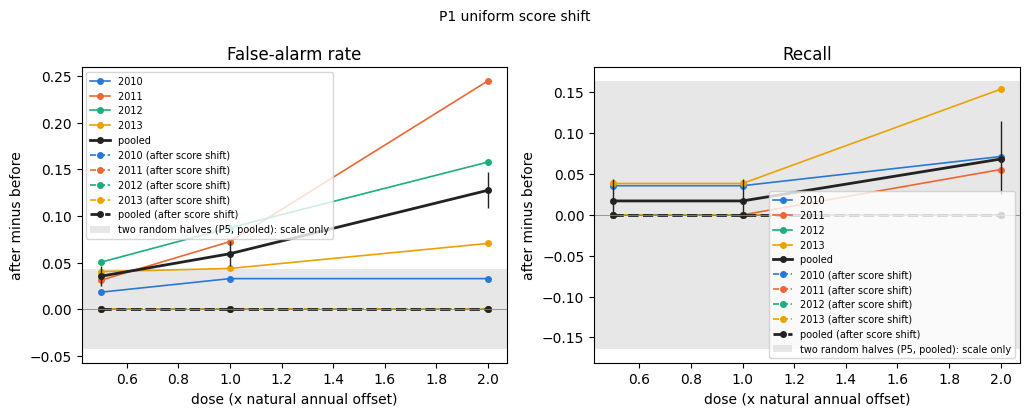

In [9]:
def dose_figure(plant, xvalues, xlabel, panels, path, title):
    fig, axes = plt.subplots(1, len(panels), figsize=(5.2 * len(panels), 4.2), squeeze=False)
    for ax, (panel_title, lines) in zip(axes[0], panels.items()):
        for (table, level, measure), style in lines:
            t = collect(plant, table)
            t = t[(t['level'] == level) & (t['measure'] == measure)]
            for predictor, part in t.groupby('predictor', sort=False):
                part = part.set_index('dose').loc[list(xvalues)]
                x = np.array(list(xvalues.values()))
                ax.plot(x, part['value'], style, color=COLORS[predictor], lw=2 if predictor == 'pooled' else 1.2, marker='o', ms=4,
                        label=f'{predictor} {"(" + level + ")" if style == "--" else ""}')
                if predictor == 'pooled':
                    ax.vlines(x, part['low'], part['high'], color=COLORS[predictor], lw=1)
        if 'no_change_spread' in globals():
            table, level, measure = lines[0][0]
            band = no_change_spread.query("level == @level and measure == @measure and predictor == @SUMMARY and item == ''")
            if len(band):
                ax.axhspan(band['random_halves_low'].iloc[0], band['random_halves_high'].iloc[0], color='#bbbbbb', alpha=.35, lw=0,
                           label='two random halves (P5, pooled): scale only')
        ax.axhline(0, color='#888888', lw=.6)
        ax.set(title=panel_title, xlabel=xlabel, ylabel='after minus before')
        ax.legend(fontsize=7)
    fig.suptitle(title, fontsize=10)
    fig.tight_layout(); fig.savefig(OUTPUT / path, dpi=130); plt.show()

P1_X = {f'{m:g}x': m for m in DOSE_MULTIPLIERS}
P1_PANELS = {'False-alarm rate': [(('what_moved', 'what moved', 'false_alarm_rate'), '-'), (('what_moved', 'after score shift', 'false_alarm_rate'), '--')],
             'Recall': [(('what_moved', 'what moved', 'recall'), '-'), (('what_moved', 'after score shift', 'recall'), '--')]}
dose_figure('P1', P1_X, 'dose (x natural annual offset)', P1_PANELS, 'figure_1_p1_dose_response.png', 'P1 uniform score shift')

**Figure 2. Under a uniform score shift, do concepts look like findings in the raw contrast but not against the score-alone expectation?** Every concept of the four predictors (rule membership, the profile's own quantity; inside the rule), dose 1x; points with patient intervals, ordered by the raw change.

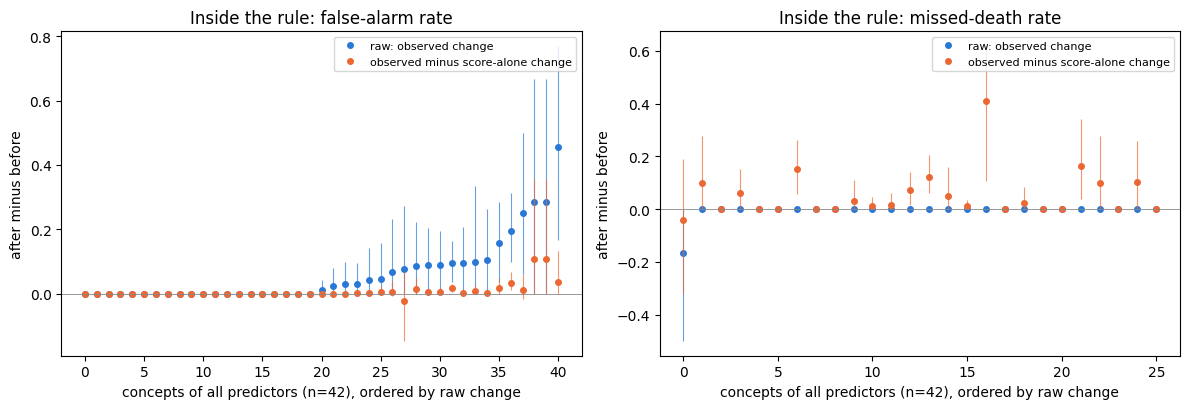

In [10]:
def concept_panel(ax, t, measure_suffix, color, label, x_order):
    part = t[t['measure'].str.endswith(measure_suffix)].set_index(['predictor', 'item']).loc[x_order]
    x = np.arange(len(part))
    ax.vlines(x, part['low'], part['high'], color=color, lw=.8, alpha=.7)
    ax.plot(x, part['value'], 'o', color=color, ms=4, label=label)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
t = collect('P1', 'concepts').query("dose == '1x'")
for ax, side, rate in zip(axes, ('survivors', 'deaths'), ('false-alarm rate', 'missed-death rate')):
    raw = t[t['measure'] == f'rule|inside|{side}|observed'].sort_values('value')
    order = list(zip(raw['predictor'], raw['item']))
    concept_panel(ax, t, f'rule|inside|{side}|observed', '#2a78d6', 'raw: observed change', order)
    concept_panel(ax, t, f'rule|inside|{side}|observed_minus_score_alone', '#eb6834', 'observed minus score-alone change', order)
    ax.axhline(0, color='#888888', lw=.6)
    ax.set(title=f'Inside the rule: {rate}', xlabel=f'concepts of all predictors (n={len(order)}), ordered by raw change', ylabel='after minus before')
    ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUTPUT / 'figure_2_p1_concepts_raw_vs_score_alone.png', dpi=130); plt.show()

## P2. Record-length mix change (survivors reweighted)

In [11]:
rows, tilt = [], {}
for ref, case in cases.items():
    frame = case['views']['evaluation']['frame']
    survivors = frame[frame['label'] == 0].groupby('year')['active_months'].mean()
    side = before[ref]['frame']
    for drop in MONTH_DROPS:
        tilt[(ref, drop)] = checks.tilt_weights(side['active_months'], side['label'], drop)
    rows.append(dict(reference=ref, survivors_mean_months_by_year=' '.join(f'{y}:{v:.2f}' for y, v in survivors.items()),
                     largest_natural_year_to_year_change=float(np.abs(np.diff(survivors.to_numpy())).max()),
                     survivors_mean_months_before=float(side.loc[side['label'] == 0, 'active_months'].mean()),
                     **{f'lambda_drop_{d:g}': tilt[(ref, d)][1] for d in MONTH_DROPS},
                     **{f'largest_weight_drop_{d:g}': float(tilt[(ref, d)][0].max()) for d in MONTH_DROPS}))
p2_doses = pd.DataFrame(rows)
p2_doses.to_csv(OUTPUT / 'p2_doses.csv', index=False)
display(p2_doses)

tick = time.perf_counter()
for drop in MONTH_DROPS:
    afters = {ref: {**before[ref], 'weight': before[ref]['weight'] * tilt[(ref, drop)][0]} for ref in cases}
    run('P2', f'-{drop:g} months', afters)
timings['P2'] = time.perf_counter() - tick
display(wide('P2', HEADLINE))
display(concept_summary('P2'))
print(FACTOR_NOTE)
display(concept_summary('P2', 'factor active'))

,reference,survivors_mean_months_by_year,largest_natural_year_to_year_change,survivors_mean_months_before,lambda_drop_0.5,lambda_drop_1,lambda_drop_2,largest_weight_drop_0.5,largest_weight_drop_1,largest_weight_drop_2
0,2010,2010:8.03 2011:8.72 2012:8.89 2013:8.96 2014:9.10,0.686061,8.716364,0.028506,0.055041,0.105170,1.237311,1.488624,2.033313
1,2011,2011:9.05 2012:9.13 2013:8.73 2014:9.26,0.531336,9.134483,0.030544,0.058417,0.109859,1.272469,1.563425,2.200067
2,2012,2012:8.81 2013:8.82 2014:9.70,0.876860,8.818792,0.030645,0.059274,0.113728,1.261183,1.544169,2.178708
3,2013,2013:9.04 2014:9.54,0.503356,9.540268,0.037087,0.070090,0.129492,1.360259,1.759295,2.674127


false-alarm rate change  \
dose        predictor                               
-0.5 months 2010       +0.0030 [+0.0005, +0.0060]   
            2011       +0.0468 [+0.0405, +0.0520]   
            2012       +0.0356 [+0.0290, +0.0420]   
            2013       +0.0317 [+0.0240, +0.0395]   
            pooled     +0.0297 [+0.0258, +0.0331]   
-1 months   2010       +0.0055 [+0.0007, +0.0115]   
            2011       +0.0926 [+0.0809, +0.1025]   
            2012       +0.0712 [+0.0582, +0.0840]   
            2013       +0.0626 [+0.0473, +0.0778]   
            pooled     +0.0588 [+0.0512, +0.0655]   
-2 months   2010       +0.0095 [+0.0000, +0.0215]   
            2011       +0.1816 [+0.1597, +0.1995]   
            2012       +0.1427 [+0.1165, +0.1673]   
            2013       +0.1225 [+0.0915, +0.1514]   
            pooled     +0.1157 [+0.1008, +0.1288]   

                      false-alarm change after score shift  \
dose        predictor                                        
-0.5 months 2010                -0.0006 [-0.0098, +0.0049]   
            2011                -0.0075 [-0.0336, +0.0256]   
            2012                +0.0015 [-0.0190, +0.0219]   
            2013                +0.0002 [-0.0234, +0.0186]   
            pooled              -0.0016 [-0.0122, +0.0109]   
-1 months   2010                -0.0009 [-0.0109, +0.0088]   
            2011                +0.0044 [-0.0442, +0.0403]   
            2012                +0.0075 [-0.0187, +0.0420]   
            2013                +0.0080 [-0.0190, +0.0407]   
            pooled              +0.0049 [-0.0092, +0.0224]   
-2 months   2010                +0.0040 [-0.0168, +0.0155]   
            2011                -0.0058 [-0.0685, +0.0509]   
            2012                +0.0439 [+0.0019, +0.0839]   
            2013                +0.0333 [-0.0133, +0.0737]   
            pooled              +0.0193 [-0.0042, +0.0393]   

                                    recall change  \
dose        predictor                               
-0.5 months 2010       +0.0000 [+0.0000, +0.0000]   
            2011       +0.0000 [+0.0000, +0.0000]   
            2012       +0.0000 [+0.0000, +0.0000]   
            2013       +0.0000 [+0.0000, +0.0000]   
            pooled     +0.0000 [+0.0000, +0.0000]   
-1 months   2010       +0.0000 [+0.0000, +0.0000]   
            2011       +0.0000 [+0.0000, +0.0000]   
            2012       +0.0000 [+0.0000, +0.0000]   
            2013       +0.0000 [+0.0000, +0.0000]   
            pooled     +0.0000 [+0.0000, +0.0000]   
-2 months   2010       +0.0000 [+0.0000, +0.0000]   
            2011       +0.0000 [+0.0000, +0.0000]   
            2012       +0.0000 [+0.0000, +0.0000]   
            2013       +0.0000 [+0.0000, +0.0000]   
            pooled     +0.0000 [+0.0000, +0.0000]   

                      recall change after score shift  \
dose        predictor                                   
-0.5 months 2010           +0.0000 [+0.0000, +0.0000]   
            2011           -0.0556 [-0.1429, +0.0000]   
            2012           -0.2593 [-0.4545, -0.0800]   
            2013           -0.0769 [-0.2084, +0.0000]   
            pooled         -0.0940 [-0.1505, -0.0451]   
-1 months   2010           +0.0000 [+0.0000, +0.0000]   
            2011           -0.2222 [-0.3871, -0.0651]   
            2012           -0.2963 [-0.4688, -0.1250]   
            2013           -0.1154 [-0.2800, +0.0000]   
            pooled         -0.1624 [-0.2353, -0.0971]   
-2 months   2010           +0.0000 [+0.0000, +0.0000]   
            2011           -0.2778 [-0.4375, -0.1316]   
            2012           -0.2963 [-0.5238, -0.1429]   
            2013           -0.2692 [-0.4483, -0.0870]   
            pooled         -0.2137 [-0.2941, -0.1417]   

                      survivors: mix (record length)  \
dose        predictor                                  
-0.5 months 2010          +0.0030 [+0.0005, +0.0060]   
            2011          +0.

concepts              \
version                         observed score_alone   
dose        predictor side                             
-0.5 months 2010      deaths           7           7   
                      survivors        7           7   
            2011      deaths          14          14   
                      survivors       14          14   
            2012      deaths           7           7   
                      survivors        7           7   
            2013      deaths          14          14   
                      survivors       14          14   
-1 months   2010      deaths           7           7   
                      survivors        7           7   
            2011      deaths          14          14   
                      survivors       14          14   
            2012      deaths           7           7   
                      survivors        7           7   
            2013      deaths          14          14   
                      survivors       14          14   
-2 months   2010      deaths           7           7   
                      survivors        7           7   
            2011      deaths          14          14   
                      survivors       14          14   
            2012      deaths           7           7   
                      survivors        7           7   
            2013      deaths          14          14   
                      survivors       14          14   

                                                            defined  \
version                         observed_minus_score_alone observed   
dose        predictor side                                            
-0.5 months 2010      deaths                             7        5   
                      survivors                          7        7   
            2011      deaths                            14        9   
                      survivors                         14       14   
            2012      deaths                             7        5   
                      survivors                          7        7   
            2013      deaths                            14        7   
                      survivors                         14       13   
-1 months   2010      deaths                             7        5   
                      survivors                          7        7   
            2011      deaths                            14        9   
                      survivors                         14       14   
            2012      deaths                             7        5   
                      survivors                          7        7   
            2013      deaths                            14        7   
                      survivors                         14       13   
-2 months   2010      deaths                             7        5   
                      survivors                          7        7   
            2011      deaths                            14        9   
                      survivors                         14       14   
            2012      deaths                             7        5   
                      survivors                          7        7   
            2013      deaths                            14        7   
                      survivors                         14       13   

                                                                        \
version                         score_alone observed_minus_score_alone   
dose        predictor side                                               
-0.5 months 2010      deaths              7                          5   
                      survivors           7                          7   
            2011      deaths             14                          9   
                      survivors          14                         14   
            2012      deaths              7                          5   
         

Factor active: a new quantity, not computed by the original profile (which uses rule membership only).


concepts              \
version                         observed score_alone   
dose        predictor side                             
-0.5 months 2010      deaths           7           7   
                      survivors        7           7   
            2011      deaths          14          14   
                      survivors       14          14   
            2012      deaths           7           7   
                      survivors        7           7   
            2013      deaths          14          14   
                      survivors       14          14   
-1 months   2010      deaths           7           7   
                      survivors        7           7   
            2011      deaths          14          14   
                      survivors       14          14   
            2012      deaths           7           7   
                      survivors        7           7   
            2013      deaths          14          14   
                      survivors       14          14   
-2 months   2010      deaths           7           7   
                      survivors        7           7   
            2011      deaths          14          14   
                      survivors       14          14   
            2012      deaths           7           7   
                      survivors        7           7   
            2013      deaths          14          14   
                      survivors       14          14   

                                                            defined  \
version                         observed_minus_score_alone observed   
dose        predictor side                                            
-0.5 months 2010      deaths                             7        5   
                      survivors                          7        7   
            2011      deaths                            14        9   
                      survivors                         14       14   
            2012      deaths                             7        6   
                      survivors                          7        7   
            2013      deaths                            14        8   
                      survivors                         14       12   
-1 months   2010      deaths                             7        5   
                      survivors                          7        7   
            2011      deaths                            14        9   
                      survivors                         14       14   
            2012      deaths                             7        6   
                      survivors                          7        7   
            2013      deaths                            14        8   
                      survivors                         14       12   
-2 months   2010      deaths                             7        5   
                      survivors                          7        7   
            2011      deaths                            14        9   
                      survivors                         14       14   
            2012      deaths                             7        6   
                      survivors                          7        7   
            2013      deaths                            14        8   
                      survivors                         14       12   

                                                                        \
version                         score_alone observed_minus_score_alone   
dose        predictor side                                               
-0.5 months 2010      deaths              7                          5   
                      survivors           7                          7   
            2011      deaths             14                          9   
                      survivors          14                         14   
            2012      deaths              7                          6   
         

Natural year-to-year changes use every evaluation year of the predictor (reference year through 2014), survivors only. Deaths keep weight 1 and survivors' total weight is unchanged, so the death rate is unchanged; the tilt weights are fixed per patient and multiply the bootstrap weights. The intervals therefore reflect patient sampling for one fixed reweighting, not uncertainty about real changes in record-length mix.

**Figure 3. Does a pure record-length mix change land entirely on 'mix', how much does the score shift absorb, and what does the shift do to recall?** Solid: raw change; dashed: after the score shift; grey band: two random halves of different patients (scale only).

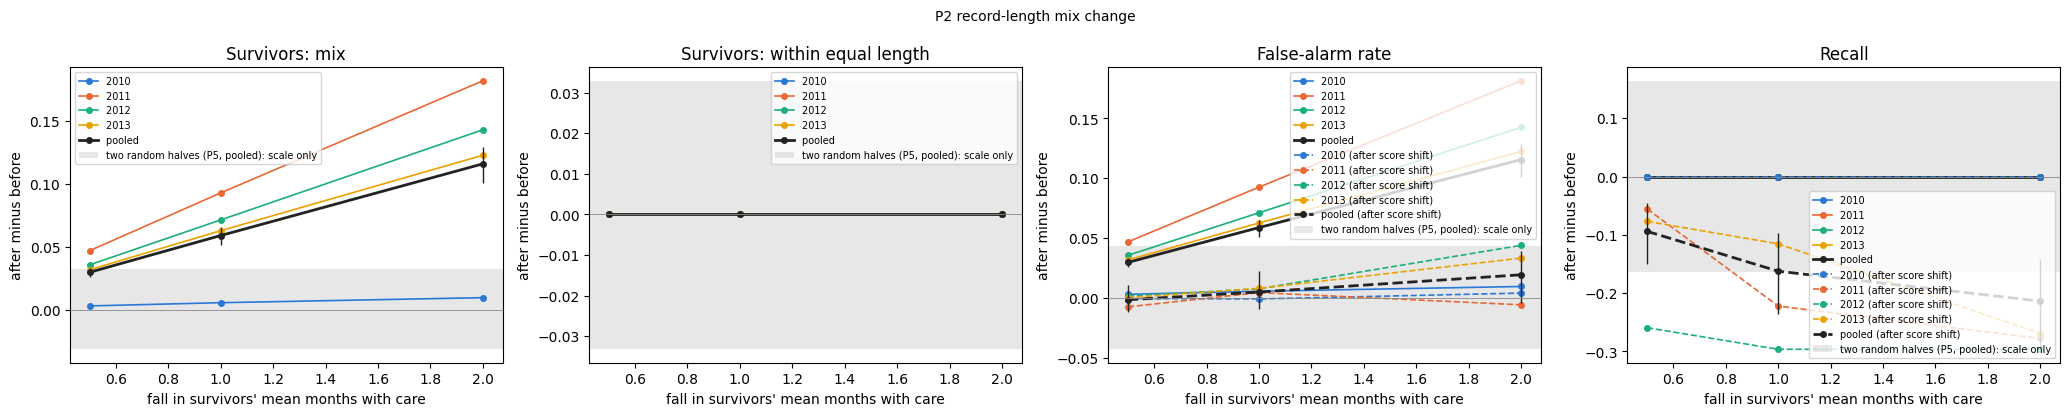

In [12]:
P2_X = {f'-{d:g} months': d for d in MONTH_DROPS}
P2_PANELS = {'Survivors: mix': [(('record_length', 'record length', 'survivors|mix'), '-')],
             'Survivors: within equal length': [(('record_length', 'record length', 'survivors|within'), '-')],
             'False-alarm rate': [(('what_moved', 'what moved', 'false_alarm_rate'), '-'), (('what_moved', 'after score shift', 'false_alarm_rate'), '--')],
             'Recall': [(('what_moved', 'what moved', 'recall'), '-'), (('what_moved', 'after score shift', 'recall'), '--')]}
dose_figure('P2', P2_X, "fall in survivors' mean months with care", P2_PANELS, 'figure_3_p2_dose_response.png', 'P2 record-length mix change')

## P3 / P4. Saved recording stops and placebo stop

In [13]:
tick = time.perf_counter()
uses, stop_rows = {}, []
for shift in checks.SHIFTS:
    afters = {}
    for ref, case in cases.items():
        s = stored[ref]
        afters[ref] = checks.make_side(before[ref]['frame'].assign(probability=s[f'{shift}|probability']), s[f'{shift}|features'],
                                       {seed: s[f'{shift}|codes_{seed}'] for seed in (42, 135, 215)}, case['concepts'])
        feature = checks.STOPPED.get(shift, str(s['placebo']))
        j = names.index(feature)
        had = before[ref]['features'][:, j] > 0
        changed = np.flatnonzero((afters[ref]['features'] != before[ref]['features']).any(axis=0))
        member_change = {d: int(np.any([afters[ref]['members'][k] != v for k, v in before[ref]['members'].items() if k[1] == d], axis=0).sum())
                         for d in ('rule', 'factor active')}
        stop_rows.append(dict(shift=shift, reference=ref, stopped_feature=feature, saved_changed_rows=int(s[f'{shift}|changed_rows']),
                              rows_changed_here=int((afters[ref]['features'] != before[ref]['features']).any(axis=1).sum()),
                              columns_changed=' '.join(names[c] for c in changed),
                              patients_with_any_rule_membership_change=member_change['rule'],
                              patients_with_any_factor_active_change_new_quantity=member_change['factor active']))
        flips.append(dict(plant='P4' if shift == 'placebo_stop' else 'P3', dose=shift, reference=ref,
                          **checks.flag_flips(before[ref], afters[ref], thresholds[ref], had)))
        for c in case['concepts']:
            uses[(shift, str(ref), c['record']['concept'])] = feature in c['record']['rule_features']
    run('P4' if shift == 'placebo_stop' else 'P3', shift, afters)
timings['P3 and P4'] = time.perf_counter() - tick
display(pd.DataFrame(stop_rows))

,shift,reference,stopped_feature,saved_changed_rows,rows_changed_here,columns_changed,patients_with_any_rule_membership_change,patients_with_any_factor_active_change_new_quantity
0,hd_stop_half,2010,EVENT_C1DIALISE_HD,57,57,EVENT_C1DIALISE_HD,37,33
1,hd_stop_half,2011,EVENT_C1DIALISE_HD,72,72,EVENT_C1DIALISE_HD,71,72
2,hd_stop_half,2012,EVENT_C1DIALISE_HD,70,70,EVENT_C1DIALISE_HD,44,57
3,hd_stop_half,2013,EVENT_C1DIALISE_HD,76,76,EVENT_C1DIALISE_HD,53,71
4,hd_stop_all,2010,EVENT_C1DIALISE_HD,114,114,EVENT_C1DIALISE_HD,64,59
5,hd_stop_all,2011,EVENT_C1DIALISE_HD,144,144,EVENT_C1DIALISE_HD,143,143
6,hd_stop_all,2012,EVENT_C1DIALISE_HD,141,141,EVENT_C1DIALISE_HD,92,111
7,hd_stop_all,2013,EVENT_C1DIALISE_HD,153,153,EVENT_C1DIALISE_HD,110,137
8,n180_stop_all,2010,DIAGN_N180,194,194,DIAGN_N180,101,95
9,n180_stop_all,2011,DIAGN_N180,216,216,DIAGN_N180,211,209


**(b) Flipped flags.** Every flag that flips should belong to a patient who had the stopped feature; patients without it should have identical scores. For the placebo (P4) the largest score change among patients who had it is the last column: the placebo is a model input, so these scores may move slightly.

In [14]:
flip_table = pd.DataFrame(flips)
flip_table.to_csv(OUTPUT / 'flag_flips.csv', index=False)
display(flip_table.query("plant in ['P3', 'P4']"))
display(flip_table.query("plant == 'P4'")[['reference', 'patients_with_feature', 'max_score_change_with_feature', 'max_score_change_without_feature',
                                          'survivors_newly_flagged', 'deaths_no_longer_flagged', 'flips_without_feature']]
        .rename(columns={'max_score_change_with_feature': 'P4: largest score change, patients with the placebo'}))

,plant,dose,reference,deaths_newly_flagged,deaths_no_longer_flagged,survivors_newly_flagged,survivors_no_longer_flagged,patients_with_feature,flips_without_feature,max_score_change_without_feature,max_score_change_with_feature
12,P3,hd_stop_half,2010,0,1,0,11,114.0,0.0,0.0,0.249361
13,P3,hd_stop_half,2011,0,3,0,3,144.0,0.0,0.0,0.308134
14,P3,hd_stop_half,2012,0,3,0,4,141.0,0.0,0.0,0.203164
15,P3,hd_stop_half,2013,0,4,0,16,153.0,0.0,0.0,0.194089
16,P3,hd_stop_all,2010,0,6,0,13,114.0,0.0,0.0,0.258837
17,P3,hd_stop_all,2011,0,4,0,5,144.0,0.0,0.0,0.309033
18,P3,hd_stop_all,2012,0,3,0,9,141.0,0.0,0.0,0.203562
19,P3,hd_stop_all,2013,0,6,0,31,153.0,0.0,0.0,0.194089
20,P3,n180_stop_all,2010,0,3,2,4,194.0,0.0,0.0,0.199960
21,P3,n180_stop_all,2011,1,0,113,0,216.0,0.0,0.0,0.210535


,reference,patients_with_feature,"P4: largest score change, patients with the placebo",max_score_change_without_feature,survivors_newly_flagged,deaths_no_longer_flagged,flips_without_feature
24,2010,15.0,0.001389,0.0,0,0,0.0
25,2011,19.0,0.004951,0.0,0,0,0.0
26,2012,14.0,0.013324,0.0,1,0,0.0
27,2013,13.0,0.001885,0.0,0,0,0.0


**(a) Rank of the stopped feature among all features.** The profile notebook orders features by the entrants' later difference; here there are no entrants, so features are ranked by the size of their after-minus-before contrast change (1 = largest), and by size over interval width. In the 'all' view the stopped feature is the only feature whose values change, so its rank there is mechanical; the error-vs-correct views also change mechanically for it (its values become 0). An empty group (e.g. no false alarms left) makes a view undefined.

In [15]:
rows = []
for (plant, dose), r in results.items():
    if plant not in ('P3', 'P4'):
        continue
    t = r['features']
    for predictor, part in t.groupby('predictor', sort=False):
        feature = checks.STOPPED.get(dose) or str(stored[REFERENCES[0]]['placebo'])
        hit = part[part['item'] == feature]
        for row in hit.itertuples():
            rows.append(dict(plant=plant, shift=dose, predictor=predictor, feature=feature, view=row.view, change=row.value,
                             low=row.low, high=row.high, rank_by_size=row.rank_by_size,
                             rank_by_size_over_interval=row.rank_by_size_over_interval, features_with_defined_change=int(part.loc[part['view'] == row.view, 'value'].notna().sum())))
feature_ranks = pd.DataFrame(rows)
assert all(str(stored[r]['placebo']) == str(stored[REFERENCES[0]]['placebo']) for r in cases)
feature_ranks.to_csv(OUTPUT / 'p3_p4_feature_ranks.csv', index=False)
display(feature_ranks.pivot_table(index=['shift', 'predictor'], columns='view', values='rank_by_size', aggfunc='first'))
display(feature_ranks.pivot_table(index=['shift', 'predictor'], columns='view', values='rank_by_size_over_interval', aggfunc='first'))

view                     all  same_outcome_deaths  same_outcome_survivors  \
shift         predictor                                                     
hd_stop_all   2010       1.0                  1.0                     NaN   
              2011       1.0                  9.0                     1.0   
              2012       1.0                 11.0                     1.0   
              2013       1.0                  5.0                     1.0   
              pooled     1.0                  4.0                     1.0   
hd_stop_half  2010       1.0                  1.0                     4.0   
              2011       1.0                  4.0                     1.0   
              2012       1.0                  8.0                     1.0   
              2013       1.0                  4.0                     1.0   
              pooled     1.0                  2.0                     1.0   
n180_stop_all 2010       1.0                  1.0                     9.0   
              2011       1.0                  5.0                     4.0   
              2012       1.0                  1.0                     1.0   
              2013       1.0                  2.0                     4.0   
              pooled     1.0                  1.0                     3.0   
placebo_stop  2010       1.0                  1.0                     1.0   
              2011       1.0                  1.0                     1.0   
              2012       1.0                  1.0                     1.0   
              2013       1.0                  1.0                     1.0   
              pooled     1.0                  1.0                     1.0   

view                     same_prediction_flagged  same_prediction_unflagged  
shift         predictor                                                      
hd_stop_all   2010                           NaN                        1.0  
              2011                           1.0                        3.0  
              2012                           8.0                        2.0  
              2013                           1.0                        1.0  
              pooled                         4.0                        1.0  
hd_stop_half  2010                          15.0                        1.0  
              2011                           1.0                        9.0  
              2012                           4.0                        2.0  
              2013                           5.0                        3.0  
              pooled                         1.0                        1.0  
n180_stop_all 2010                           1.0                        1.0  
              2011                           7.0                        1.0  
              2012                           8.0                        1.0  
              2013                           6.0                       11.0  
              pooled                        32.0                        2.0  
placebo_stop  2010                           1.0                        1.0  
              2011                           1.0                        1.0  
              2012                          41.0                        1.0  
              2013                           1.0                        1.0  
              pooled                         3.0                        1.0

view                     all  same_outcome_deaths  same_outcome_survivors  \
shift         predictor                                                     
hd_stop_all   2010       1.0                 19.0                     NaN   
              2011       1.0                 30.0                     1.0   
              2012       1.0                 26.0                     1.0   
              2013       1.0                 14.0                    10.0   
              pooled     1.0                 40.0                     1.0   
hd_stop_half  2010       1.0                  1.0                    57.0   
              2011       1.0                 30.0                     1.0   
              2012       1.0                 24.0                     1.0   
              2013       1.0                 14.0                     1.0   
              pooled     1.0                 40.0                     1.0   
n180_stop_all 2010       1.0                  1.0                    71.0   
              2011       1.0                 30.0                     2.0   
              2012       1.0                  1.0                     1.0   
              2013       1.0                  2.0                     2.0   
              pooled     1.0                  1.0                     2.0   
placebo_stop  2010       1.0                  NaN                     1.0   
              2011       1.0                  1.0                     1.0   
              2012       1.0                  NaN                     1.0   
              2013       1.0                  NaN                     1.0   
              pooled     1.0                  1.0                     1.0   

view                     same_prediction_flagged  same_prediction_unflagged  
shift         predictor                                                      
hd_stop_all   2010                           NaN                       73.0  
              2011                           1.0                       43.0  
              2012                          42.0                       51.0  
              2013                          24.0                        9.0  
              pooled                        75.0                        7.0  
hd_stop_half  2010                          23.0                       73.0  
              2011                           1.0                       42.0  
              2012                          43.0                       30.0  
              2013                          31.0                       67.0  
              pooled                        66.0                      110.0  
n180_stop_all 2010                           1.0                        1.0  
              2011                          64.0                       21.0  
              2012                          51.0                        8.0  
              2013                          11.0                       57.0  
              pooled                       100.0                       27.0  
placebo_stop  2010                           NaN                        1.0  
              2011                           1.0                        1.0  
              2012                           NaN                        1.0  
              2013                           NaN                        1.0  
              pooled                         4.0                        1.0

**(c) Concept ranks.** Inside-the-rule error-rate change per concept, ranked by absolute size (1 = largest) within each predictor and jointly over all predictors ('pooled'), raw (observed) and observed minus score-alone. Listed: ranks of the concepts whose rule uses the stopped feature, and the best rank of the other concepts; 'defined' counts the concepts whose group holds patients of that outcome before and after (a rule emptied by the stop has no inside rate after it). The first table is rule membership (the profile's quantity); the second is factor active, a new quantity the original profile does not compute.

In [16]:
rank_tables, rows = [], []
for (plant, dose), r in results.items():
    if plant not in ('P3', 'P4'):
        continue
    ranks = checks.concept_ranks(r['concepts'], {(p, c): u for (s, p, c), u in uses.items() if s == dose})
    rank_tables.append(ranks)
    for measure, g in ranks[ranks['version'] != 'score_alone'].groupby('measure', sort=False):
        groups = [(p, g[g['predictor'] == p], 'rank_in_predictor') for p in g['predictor'].unique()] + [('pooled', g, 'rank_pooled')]
        for predictor, h, column in groups:
            using, other = h[h['uses_stopped_feature']], h[~h['uses_stopped_feature']]
            rows.append(dict(shift=dose, measure=measure, source=h['source'].iloc[0], predictor=predictor, concepts=len(h),
                             concepts_defined=int(h['value'].notna().sum()), concepts_using_feature=len(using),
                             concepts_using_feature_defined=int(using['value'].notna().sum()),
                             ranks_of_concepts_using_feature=' '.join('undefined' if not np.isfinite(x) else str(int(x)) for x in sorted(using[column])),
                             best_rank_of_other_concepts=other[column].min() if len(other) else np.nan,
                             largest_absolute_change=h['value'].abs().max()))
concept_rank_table = pd.DataFrame(rows)
pd.concat(rank_tables, ignore_index=True).to_csv(OUTPUT / 'p3_p4_concept_ranks.csv.gz', index=False)
concept_rank_table.to_csv(OUTPUT / 'p3_p4_concept_rank_summary.csv', index=False)
with pd.option_context('display.max_rows', 400, 'display.max_colwidth', 80):
    display(concept_rank_table[concept_rank_table['measure'].str.startswith('rule|')])
    print(FACTOR_NOTE)
    display(concept_rank_table[concept_rank_table['measure'].str.startswith('factor active|')])

,shift,measure,source,predictor,concepts,concepts_defined,concepts_using_feature,concepts_using_feature_defined,ranks_of_concepts_using_feature,best_rank_of_other_concepts,largest_absolute_change
0,hd_stop_half,rule|inside|deaths|observed,profile quantity: rule membership,2010,7,5,6,5,1 2 2 2 2 undefined,NaN,0.250000
1,hd_stop_half,rule|inside|deaths|observed,profile quantity: rule membership,2011,14,8,8,4,2 undefined 2 undefined undefined 2 undefined 2,1.0,0.428571
2,hd_stop_half,rule|inside|deaths|observed,profile quantity: rule membership,2012,7,4,4,3,1 2 undefined 2,2.0,0.222222
3,hd_stop_half,rule|inside|deaths|observed,profile quantity: rule membership,2013,14,5,8,2,5 undefined undefined 1 undefined undefined undefined undefined,2.0,0.500000
4,hd_stop_half,rule|inside|deaths|observed,profile quantity: rule membership,pooled,42,22,26,14,5 8 8 8 8 undefined 8 undefined 8 undefined undefined 6 8 undefined 8 8 unde...,2.0,0.500000
5,hd_stop_half,rule|inside|deaths|observed_minus_score_alone,profile quantity: rule membership,2010,7,5,6,5,1 2 3 3 5 undefined,NaN,0.431569
6,hd_stop_half,rule|inside|deaths|observed_minus_score_alone,profile quantity: rule membership,2011,14,8,8,4,6 undefined 6 undefined undefined 6 undefined 4,1.0,0.324302
7,hd_stop_half,rule|inside|deaths|observed_minus_score_alone,profile quantity: rule membership,2012,7,4,4,3,1 2 undefined 3,3.0,0.134707
8,hd_stop_half,rule|inside|deaths|observed_minus_score_alone,profile quantity: rule membership,2013,14,5,8,2,5 undefined undefined 1 undefined undefined undefined undefined,2.0,0.389844
9,hd_stop_half,rule|inside|deaths|observed_minus_score_alone,profile quantity: rule membership,pooled,42,22,26,14,1 5 6 7 7 16 undefined 13 14 16 undefined 16 undefined undefined 16 undefine...,3.0,0.431569


Factor active: a new quantity, not computed by the original profile (which uses rule membership only).


,shift,measure,source,predictor,concepts,concepts_defined,concepts_using_feature,concepts_using_feature_defined,ranks_of_concepts_using_feature,best_rank_of_other_concepts,largest_absolute_change
20,hd_stop_half,factor active|inside|deaths|observed,new quantity: factor active (not computed by the original profile),2010,7,5,6,5,1 1 3 3 3 undefined,NaN,0.017857
21,hd_stop_half,factor active|inside|deaths|observed,new quantity: factor active (not computed by the original profile),2011,14,9,8,4,2 undefined 2 undefined undefined 2 undefined 2,1.0,0.428571
22,hd_stop_half,factor active|inside|deaths|observed,new quantity: factor active (not computed by the original profile),2012,7,4,4,2,undefined 1 undefined 1,1.0,0.000000
23,hd_stop_half,factor active|inside|deaths|observed,new quantity: factor active (not computed by the original profile),2013,14,7,8,5,3 undefined undefined 3 3 3 undefined 1,2.0,0.833333
24,hd_stop_half,factor active|inside|deaths|observed,new quantity: factor active (not computed by the original profile),pooled,42,25,26,16,4 4 6 6 6 undefined 6 undefined 6 undefined undefined 6 undefined 6 undefine...,2.0,0.833333
25,hd_stop_half,factor active|inside|deaths|observed_minus_score_alone,new quantity: factor active (not computed by the original profile),2010,7,5,6,5,1 2 3 4 5 undefined,NaN,0.273771
26,hd_stop_half,factor active|inside|deaths|observed_minus_score_alone,new quantity: factor active (not computed by the original profile),2011,14,9,8,4,8 undefined 5 undefined undefined 8 undefined 6,1.0,0.291003
27,hd_stop_half,factor active|inside|deaths|observed_minus_score_alone,new quantity: factor active (not computed by the original profile),2012,7,4,4,2,undefined 1 undefined 2,2.0,0.007178
28,hd_stop_half,factor active|inside|deaths|observed_minus_score_alone,new quantity: factor active (not computed by the original profile),2013,14,7,8,5,4 undefined undefined 3 4 4 undefined 1,2.0,0.728012
29,hd_stop_half,factor active|inside|deaths|observed_minus_score_alone,new quantity: factor active (not computed by the original profile),pooled,42,25,26,16,1 3 4 5 9 11 undefined 13 14 17 undefined undefined undefined 17 undefined 1...,2.0,0.728012


**(d) How much of the change does the score-shift level absorb?** Raw change beside the change remaining after `shift_scores`.

In [17]:
display(wide('P3', HEADLINE))
display(wide('P4', HEADLINE))
display(concept_summary('P4'))
print(FACTOR_NOTE)
display(concept_summary('P4', 'factor active'))

false-alarm rate change  \
dose          predictor                               
hd_stop_half  2010       -0.0400 [-0.0643, -0.0182]   
              2011       -0.0103 [-0.0239, +0.0000]   
              2012       -0.0134 [-0.0272, -0.0033]   
              2013       -0.0537 [-0.0816, -0.0300]   
              pooled     -0.0293 [-0.0398, -0.0202]   
hd_stop_all   2010       -0.0473 [-0.0734, -0.0235]   
              2011       -0.0172 [-0.0339, -0.0034]   
              2012       -0.0302 [-0.0528, -0.0138]   
              2013       -0.1040 [-0.1407, -0.0709]   
              pooled     -0.0500 [-0.0629, -0.0385]   
n180_stop_all 2010       -0.0073 [-0.0246, +0.0106]   
              2011       +0.3897 [+0.3355, +0.4430]   
              2012       +0.2114 [+0.1635, +0.2573]   
              2013       +0.2819 [+0.2200, +0.3425]   
              pooled     +0.2222 [+0.1939, +0.2481]   

                        false-alarm change after score shift  \
dose          predictor                                        
hd_stop_half  2010                -0.0255 [-0.0489, -0.0036]   
              2011                +0.0138 [-0.0073, +0.0369]   
              2012                +0.0872 [+0.0476, +0.1365]   
              2013                -0.0101 [-0.0421, +0.0208]   
              pooled              +0.0172 [+0.0017, +0.0332]   
hd_stop_all   2010                -0.0400 [-0.0607, -0.0179]   
              2011                +0.0345 [+0.0070, +0.0709]   
              2012                +0.1510 [+0.1076, +0.1886]   
              2013                -0.0067 [-0.0381, +0.0245]   
              pooled              +0.0362 [+0.0190, +0.0520]   
n180_stop_all 2010                -0.0255 [-0.0474, -0.0072]   
              2011                +0.1207 [+0.0580, +0.1935]   
              2012                -0.0168 [-0.0636, +0.0214]   
              2013                -0.0537 [-0.0918, -0.0236]   
              pooled              +0.0060 [-0.0171, +0.0288]   

                                      recall change  \
dose          predictor                               
hd_stop_half  2010       -0.0357 [-0.1250, +0.0000]   
              2011       -0.0833 [-0.1905, +0.0000]   
              2012       -0.1111 [-0.2400, +0.0000]   
              2013       -0.1538 [-0.2964, -0.0370]   
              pooled     -0.0940 [-0.1474, -0.0461]   
hd_stop_all   2010       -0.2143 [-0.3751, -0.0625]   
              2011       -0.1111 [-0.2250, -0.0263]   
              2012       -0.1111 [-0.2400, +0.0000]   
              2013       -0.2308 [-0.4000, -0.0769]   
              pooled     -0.1624 [-0.2248, -0.0973]   
n180_stop_all 2010       -0.1071 [-0.2308, +0.0000]   
              2011       +0.0278 [+0.0000, +0.0910]   
              2012       +0.0000 [+0.0000, +0.0000]   
              2013       -0.0385 [-0.2581, +0.1538]   
              pooled     -0.0256 [-0.0826, +0.0261]   

                        recall change after score shift  \
dose          predictor                                   
hd_stop_half  2010           -0.0357 [-0.1250, +0.0000]   
              2011           -0.0556 [-0.1538, +0.0000]   
              2012           -0.1111 [-0.2400, +0.0000]   
              2013           -0.0385 [-0.1667, +0.0953]   
              pooled         -0.0598 [-0.1111, -0.0160]   
hd_stop_all   2010           -0.1429 [-0.2857, -0.0312]   
              2011           -0.0556 [-0.1516, +0.0000]   
              2012           -0.1111 [-0.2400, +0.0000]   
              2013           -0.0385 [-0.2143, +0.1819]   
              pooled         -0.0855 [-0.1491, -0.0236]   
n180_stop_all 2010           -0.1071 [-0.2502, +0.0000]   
              2011           -0.3333 [-0.5122, -0.1481]   
              2012           -0.2593 [-0.4413, -0.0869]   
              2013           -0.1538 [-0.3530, +0.0000]   
              pooled         -0.2222 [-0.3114, -0.1440]   

                        survivors: mix (record length)  \
dose 

false-alarm rate change  \
dose         predictor                               
placebo_stop 2010       +0.0000 [+0.0000, +0.0000]   
             2011       +0.0000 [+0.0000, +0.0000]   
             2012       +0.0034 [+0.0000, +0.0106]   
             2013       +0.0000 [+0.0000, +0.0000]   
             pooled     +0.0009 [+0.0000, +0.0026]   

                       false-alarm change after score shift  \
dose         predictor                                        
placebo_stop 2010                +0.0000 [+0.0000, +0.0000]   
             2011                +0.0000 [+0.0000, +0.0000]   
             2012                +0.0034 [+0.0000, +0.0106]   
             2013                +0.0000 [+0.0000, +0.0000]   
             pooled              +0.0009 [+0.0000, +0.0026]   

                                     recall change  \
dose         predictor                               
placebo_stop 2010       +0.0000 [+0.0000, +0.0000]   
             2011       +0.0000 [+0.0000, +0.0000]   
             2012       +0.0000 [+0.0000, +0.0000]   
             2013       +0.0000 [+0.0000, +0.0000]   
             pooled     +0.0000 [+0.0000, +0.0000]   

                       recall change after score shift  \
dose         predictor                                   
placebo_stop 2010           +0.0000 [+0.0000, +0.0000]   
             2011           +0.0000 [+0.0000, +0.0000]   
             2012           +0.0000 [+0.0000, +0.0000]   
             2013           +0.0000 [+0.0000, +0.0000]   
             pooled         +0.0000 [+0.0000, +0.0000]   

                       survivors: mix (record length)  \
dose         predictor                                  
placebo_stop 2010          +0.0000 [+0.0000, +0.0000]   
             2011          +0.0000 [+0.0000, +0.0000]   
             2012          +0.0000 [+0.0000, +0.0000]   
             2013          +0.0000 [+0.0000, +0.0000]   
             pooled        +0.0000 [+0.0000, +0.0000]   

                       survivors: within equal length  \
dose         predictor                                  
placebo_stop 2010          +0.0000 [+0.0000, +0.0000]   
             2011          +0.0000 [+0.0000, +0.0000]   
             2012          +0.0034 [+0.0000, +0.0106]   
             2013          +0.0000 [+0.0000, +0.0000]   
             pooled        +0.0009 [+0.0000, +0.0026]   

                       deaths: mix (record length) deaths: within equal length  
dose         predictor                                                          
placebo_stop 2010       +0.0000 [+0.0000, +0.0000]  +0.0000 [+0.0000, +0.0000]  
             2011       +0.0000 [+0.0000, +0.0000]  +0.0000 [+0.0000, +0.0000]  
             2012       +0.0000 [+0.0000, +0.0000]  +0.0000 [+0.0000, +0.0000]  
             2013       +0.0000 [+0.0000, +0.0000]  +0.0000 [+0.0000, +0.0000]  
             pooled     +0.0000 [+0.0000, +0.0000]  +0.0000 [+0.0000, +0.0000]

concepts              \
version                          observed score_alone   
dose         predictor side                             
placebo_stop 2010      deaths           7           7   
                       survivors        7           7   
             2011      deaths          14          14   
                       survivors       14          14   
             2012      deaths           7           7   
                       survivors        7           7   
             2013      deaths          14          14   
                       survivors       14          14   

                                                             defined  \
version                          observed_minus_score_alone observed   
dose         predictor side                                            
placebo_stop 2010      deaths                             7        5   
                       survivors                          7        7   
             2011      deaths                            14        9   
                       survivors                         14       14   
             2012      deaths                             7        5   
                       survivors                          7        7   
             2013      deaths                            14        7   
                       survivors                         14       13   

                                                                         \
version                          score_alone observed_minus_score_alone   
dose         predictor side                                               
placebo_stop 2010      deaths              7                          5   
                       survivors           7                          7   
             2011      deaths             14                          9   
                       survivors          14                         14   
             2012      deaths              7                          5   
                       survivors           7                          7   
             2013      deaths             13                          7   
                       survivors          13                         13   

                                 largest_absolute_change              \
version                                         observed score_alone   
dose         predictor side                                            
placebo_stop 2010      deaths                        0.0    0.000020   
                       survivors                     0.0    0.000016   
             2011      deaths                        0.0    0.001374   
                       survivors                     0.0    0.000139   
             2012      deaths                        0.0    0.000235   
                       survivors                     0.0    0.000028   
             2013      deaths                        0.0    0.000272   
                       survivors                     0.0    0.000018   

                                                             \
version                          observed_minus_score_alone   
dose         predictor side                                   
placebo_stop 2010      deaths                      0.000020   
                       survivors                   0.000016   
             2011      deaths                      0.001374   
                       survivors                   0.000139   
             2012      deaths                      0.000235   
                       survivors                   0.000028   
             2013      deaths                      0.000272   
                       survivors                   0.000018   

                                 intervals_excluding_zero              \
version                                          observed score_alone   
dose         predictor side                                             
placebo_stop 2010      deaths                           0           0   
       

Factor active: a new quantity, not computed by the original profile (which uses rule membership only).


concepts              \
version                          observed score_alone   
dose         predictor side                             
placebo_stop 2010      deaths           7           7   
                       survivors        7           7   
             2011      deaths          14          14   
                       survivors       14          14   
             2012      deaths           7           7   
                       survivors        7           7   
             2013      deaths          14          14   
                       survivors       14          14   

                                                             defined  \
version                          observed_minus_score_alone observed   
dose         predictor side                                            
placebo_stop 2010      deaths                             7        5   
                       survivors                          7        7   
             2011      deaths                            14        8   
                       survivors                         14       14   
             2012      deaths                             7        6   
                       survivors                          7        7   
             2013      deaths                            14        8   
                       survivors                         14       12   

                                                                         \
version                          score_alone observed_minus_score_alone   
dose         predictor side                                               
placebo_stop 2010      deaths              7                          5   
                       survivors           7                          7   
             2011      deaths             14                          8   
                       survivors          14                         14   
             2012      deaths              7                          6   
                       survivors           7                          7   
             2013      deaths             12                          8   
                       survivors          12                         12   

                                 largest_absolute_change              \
version                                         observed score_alone   
dose         predictor side                                            
placebo_stop 2010      deaths                   0.000000    0.000025   
                       survivors                0.000000    0.000020   
             2011      deaths                   0.090909    0.014264   
                       survivors                0.018357    0.026414   
             2012      deaths                   0.000000    0.000473   
                       survivors                0.000000    0.000083   
             2013      deaths                   0.000000    0.003217   
                       survivors                0.007459    0.007374   

                                                             \
version                          observed_minus_score_alone   
dose         predictor side                                   
placebo_stop 2010      deaths                      0.000025   
                       survivors                   0.000020   
             2011      deaths                      0.077227   
                       survivors                   0.011958   
             2012      deaths                      0.000473   
                       survivors                   0.000083   
             2013      deaths                      0.003217   
                       survivors                   0.000085   

                                 intervals_excluding_zero              \
version                                          observed score_alone   
dose         predictor side                                             
placebo_stop 2010      deaths                           0           0   
       

**Figure 7. For the recording stops, how much of the false-alarm and recall change does the score shift absorb, and what does it create?** Each row is one stop and predictor; circles: raw change; crosses: after the score shift; lines: patient intervals.

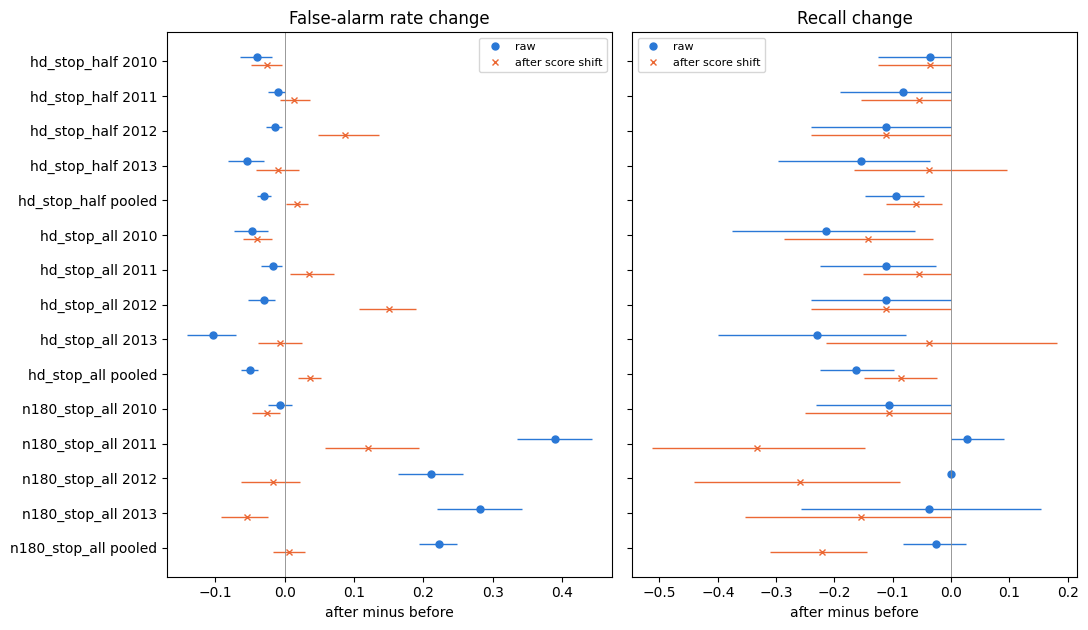

In [18]:
t = collect('P3', 'what_moved')
rows_shown = [(d, p) for d in ('hd_stop_half', 'hd_stop_all', 'n180_stop_all') for p in list(map(str, cases)) + ([SUMMARY] if SUMMARY not in map(str, cases) else [])]
fig, axes = plt.subplots(1, 2, figsize=(11, .32 * len(rows_shown) + 1.6), sharey=True)
y = np.arange(len(rows_shown))[::-1]
for ax, (metric, title) in zip(axes, (('false_alarm_rate', 'False-alarm rate change'), ('recall', 'Recall change'))):
    for level, marker, color, dy in (('what moved', 'o', '#2a78d6', .12), ('after score shift', 'x', '#eb6834', -.12)):
        part = t[(t['level'] == level) & (t['measure'] == metric)].set_index(['dose', 'predictor']).loc[rows_shown]
        ax.hlines(y + dy, part['low'], part['high'], color=color, lw=1)
        ax.plot(part['value'], y + dy, marker, color=color, ms=5, label='raw' if level == 'what moved' else 'after score shift')
    ax.axvline(0, color='#888888', lw=.6)
    ax.set(title=title, xlabel='after minus before')
    ax.legend(fontsize=8)
axes[0].set_yticks(y, [f'{d} {p}' for d, p in rows_shown])
fig.tight_layout(); fig.savefig(OUTPUT / 'figure_7_p3_score_shift_absorption.png', dpi=130); plt.show()

**Figure 4. After a recording stop, do the concepts whose rule uses the stopped feature move most, raw and against the score-alone risk?** Rule membership, the profile's own concept quantity. Each point is one concept, inside the rule, with its patient interval; blue = rule uses the stopped feature, grey = does not. Columns of points: predictors. A rule emptied by the stop has no point.

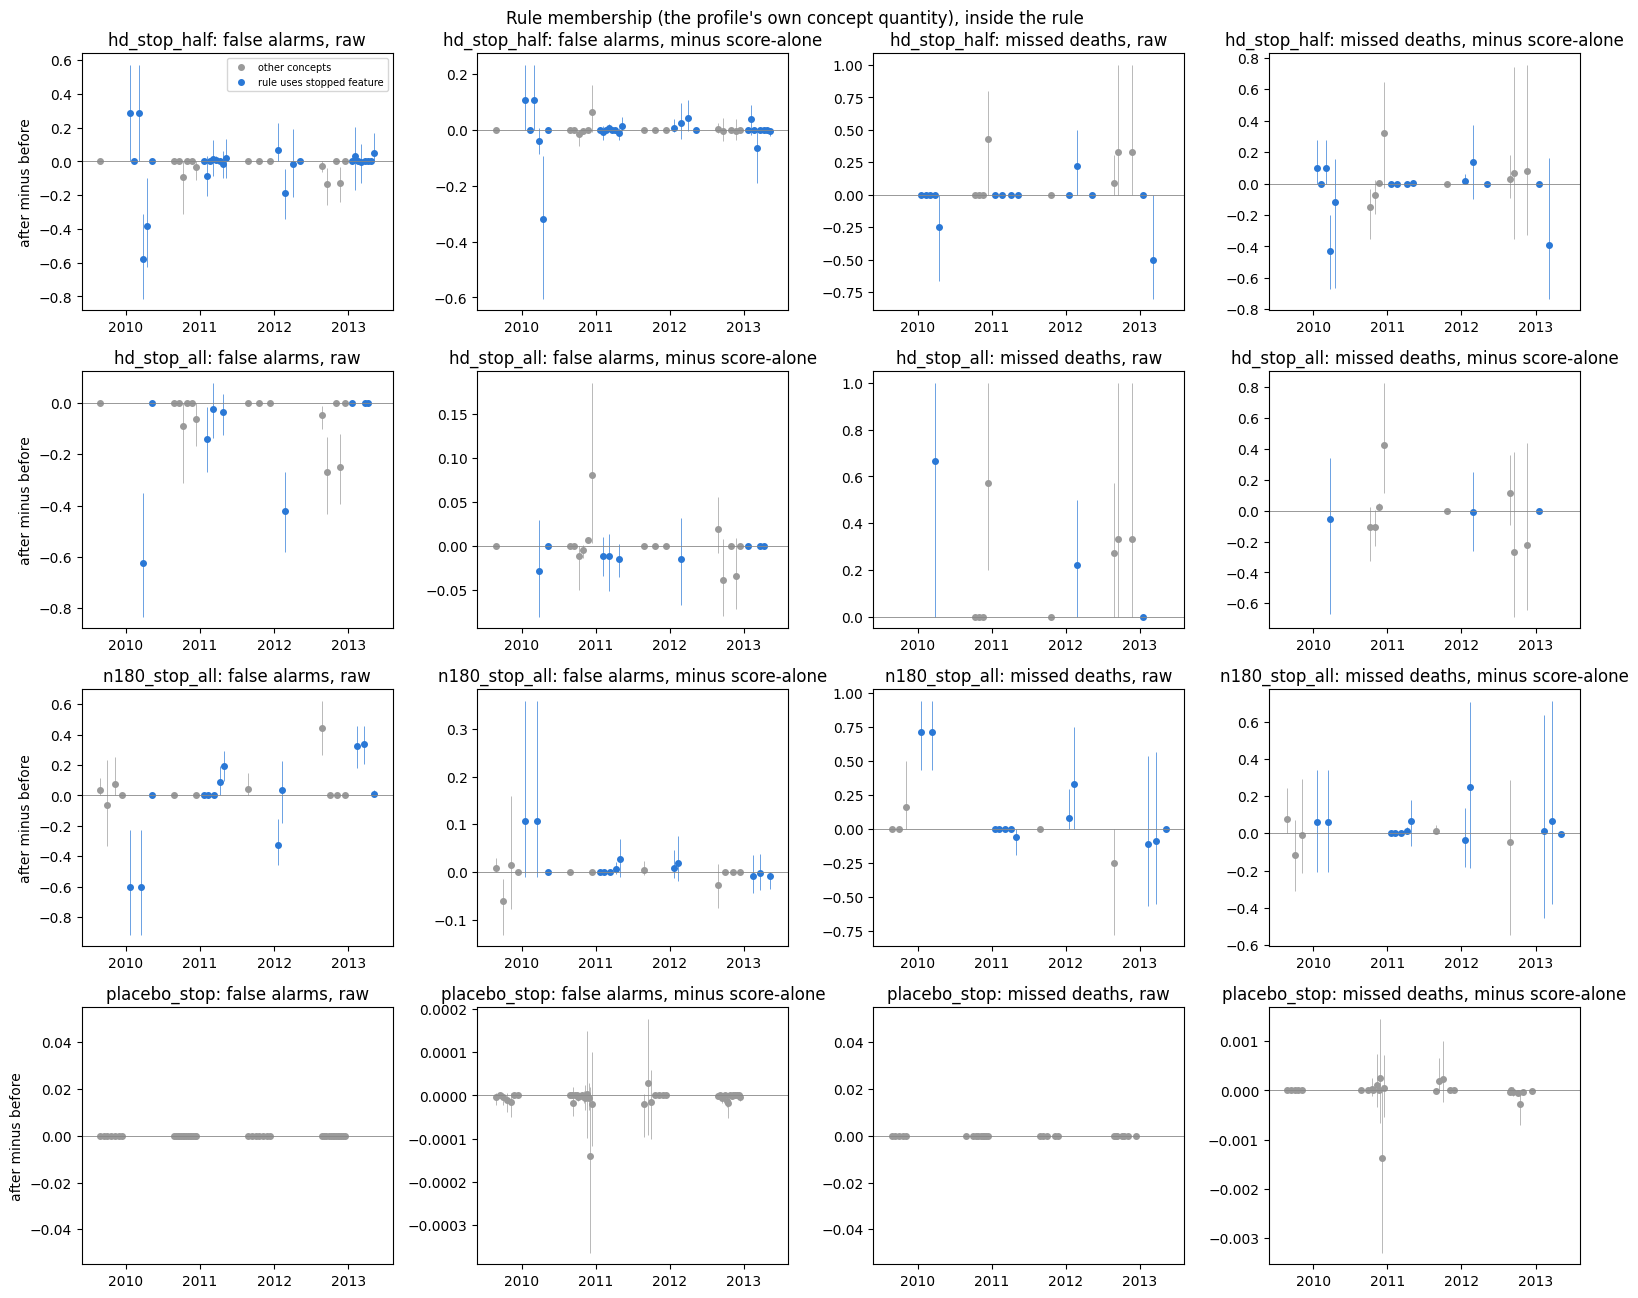

In [19]:
all_ranks = pd.concat(rank_tables, ignore_index=True)

def concept_rank_figure(definition, path, title):
    fig, axes = plt.subplots(len(checks.SHIFTS), 4, figsize=(16, 3.3 * len(checks.SHIFTS)), squeeze=False)
    panels = [('survivors', 'observed', 'false alarms, raw'), ('survivors', 'observed_minus_score_alone', 'false alarms, minus score-alone'),
              ('deaths', 'observed', 'missed deaths, raw'), ('deaths', 'observed_minus_score_alone', 'missed deaths, minus score-alone')]
    for row, shift in enumerate(checks.SHIFTS):
        t = all_ranks[all_ranks['dose'] == shift]
        for col, (side, version, panel_title) in enumerate(panels):
            ax, part = axes[row, col], t[t['measure'] == f'{definition}|inside|{side}|{version}']
            for k, ref in enumerate(map(str, cases)):
                for flag, color in ((False, '#9a9a9a'), (True, '#2a78d6')):
                    q = part[(part['predictor'] == ref) & (part['uses_stopped_feature'] == flag)]
                    x = k + (.2 if flag else -.2) + np.linspace(-.15, .15, len(q)) if len(q) else []
                    ax.vlines(x, q['low'], q['high'], color=color, lw=.7, alpha=.7)
                    ax.plot(x, q['value'], 'o', color=color, ms=4, label=('rule uses stopped feature' if flag else 'other concepts') if k == 0 else None)
            ax.axhline(0, color='#888888', lw=.6)
            ax.set_xticks(range(len(cases)), list(map(str, cases))); ax.set_xlim(-.6, len(cases) - .4)
            ax.set(title=f'{shift}: {panel_title}', ylabel='after minus before' if col == 0 else '')
            if row == 0 and col == 0:
                ax.legend(fontsize=7)
    fig.suptitle(title, fontsize=12)
    fig.tight_layout(); fig.savefig(OUTPUT / path, dpi=120); plt.show()

concept_rank_figure('rule', 'figure_4_p3_p4_concepts.png', 'Rule membership (the profile\'s own concept quantity), inside the rule')

**Figure 4b. The same for factor active — a new quantity the original profile does not compute.** Kept separate from the rule-based Figure 4; blue still means the concept's *rule* uses the stopped feature.

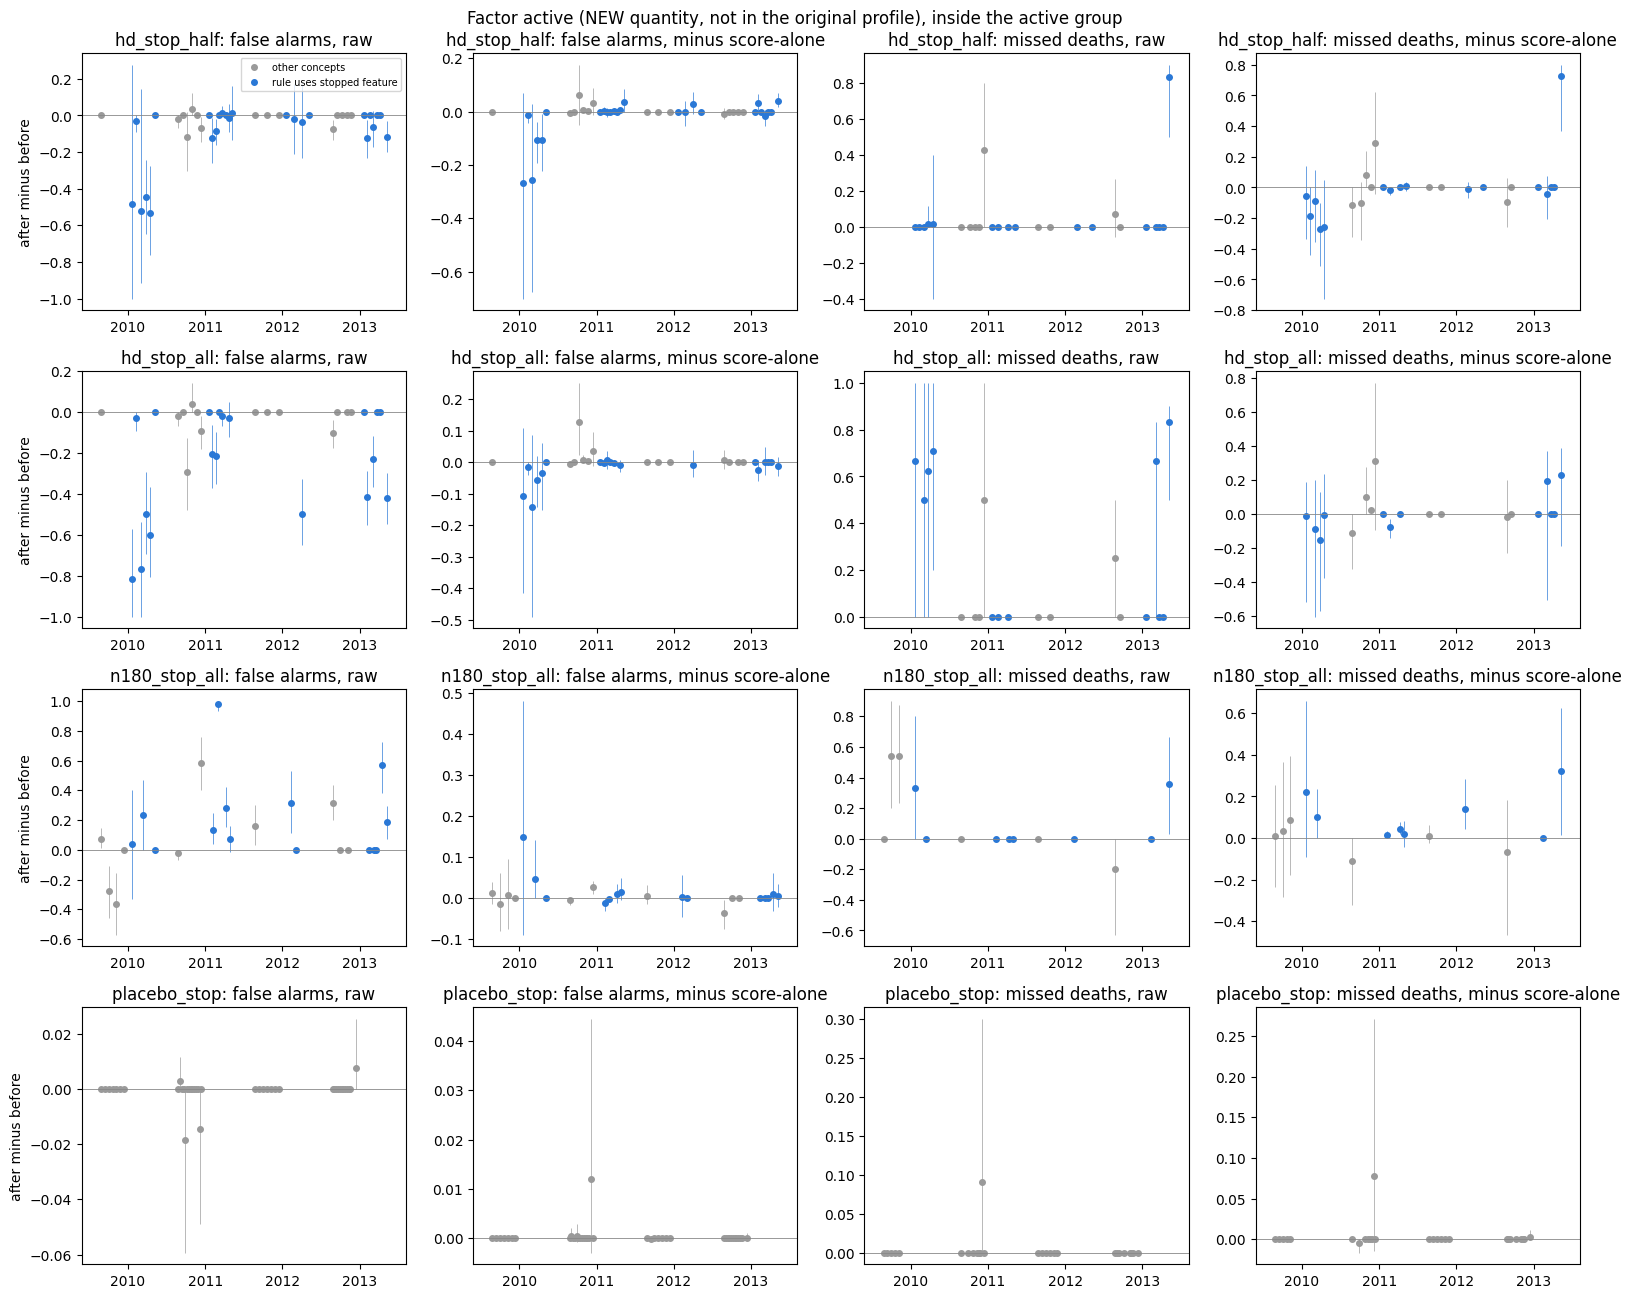

In [20]:
concept_rank_figure('factor active', 'figure_4b_p3_p4_factor_active_new_quantity.png', 'Factor active (NEW quantity, not in the original profile), inside the active group')

**Figure 5. How large is each planted estimate compared with the difference between two random halves of different patients?** Pooled over the four predictors; points with patient intervals; grey band = 2.5–97.5% of the differences between two random halves of different patients (P5). The band is a scale reference only: for a paired plant (P1–P4, same patients before and after) the value when nothing is planted is exactly 0.

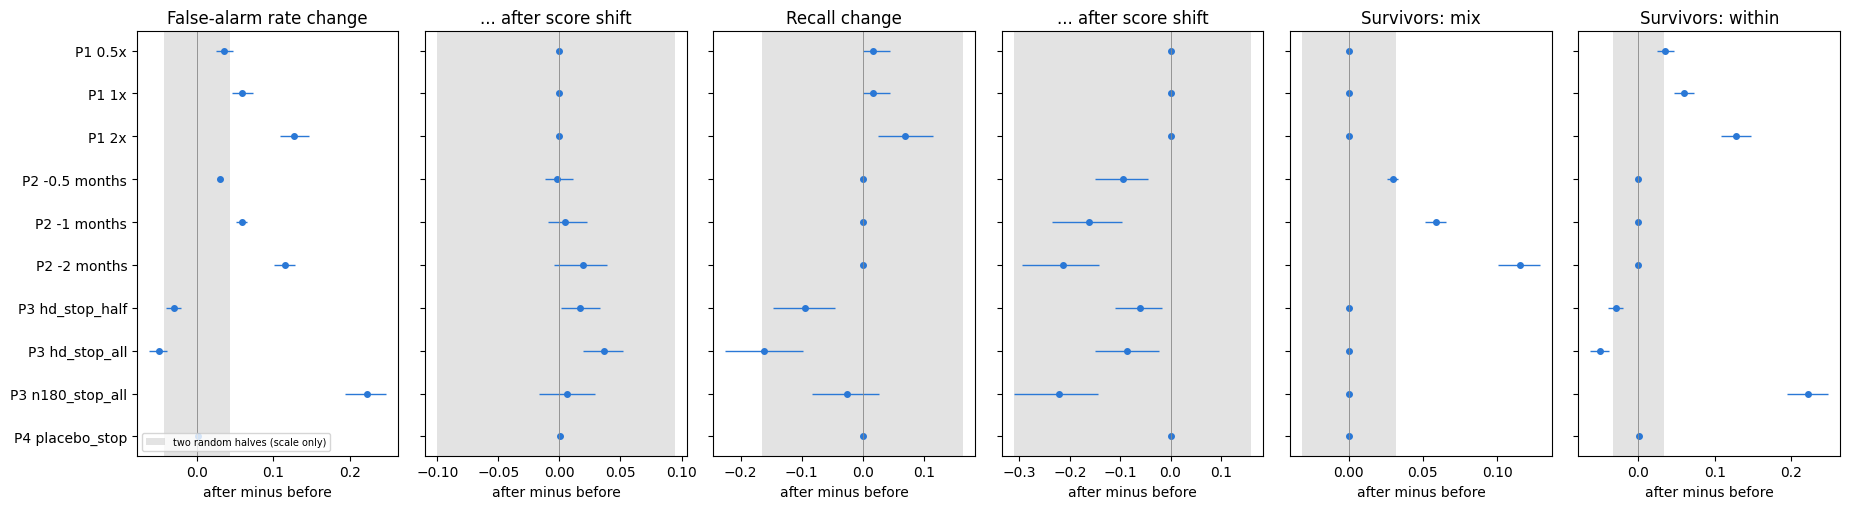

In [21]:
planted = pd.concat([checks.stack(r).assign(plant=p, dose=d) for (p, d), r in results.items()], ignore_index=True)
compared = planted.merge(no_change_spread, on=checks.KEY, how='left', validate='many_to_one')
compared.to_csv(OUTPUT / 'planted_vs_no_change.csv.gz', index=False)
labels = list(dict.fromkeys(zip(compared['plant'], compared['dose'])))
measures_shown = [('what moved', 'false_alarm_rate', 'False-alarm rate change'), ('after score shift', 'false_alarm_rate', '... after score shift'),
                  ('what moved', 'recall', 'Recall change'), ('after score shift', 'recall', '... after score shift'),
                  ('record length', 'survivors|mix', 'Survivors: mix'), ('record length', 'survivors|within', 'Survivors: within')]
fig, axes = plt.subplots(1, len(measures_shown), figsize=(3.1 * len(measures_shown), 5.2), sharey=True)
for ax, (level, measure, title) in zip(axes, measures_shown):
    t = compared.query("predictor == @SUMMARY and level == @level and measure == @measure").set_index(['plant', 'dose']).loc[labels]
    y = np.arange(len(labels))[::-1]
    ax.axvspan(t['random_halves_low'].iloc[0], t['random_halves_high'].iloc[0], color='#bbbbbb', alpha=.4, lw=0,
               label='two random halves (scale only)' if level == 'what moved' and measure == 'false_alarm_rate' else None)
    ax.hlines(y, t['low'], t['high'], color='#2a78d6', lw=1)
    ax.plot(t['value'], y, 'o', color='#2a78d6', ms=4)
    ax.axvline(0, color='#888888', lw=.6)
    ax.set(title=title, xlabel='after minus before')
axes[0].set_yticks(np.arange(len(labels))[::-1], [f'{p} {d}' for p, d in labels]); axes[0].legend(fontsize=7, loc='lower left')
fig.tight_layout(); fig.savefig(OUTPUT / 'figure_5_planted_vs_no_change.png', dpi=130); plt.show()

**Figure 6. Between two random halves of different patients, how often does a patient interval exclude 0, per level?** 100 random splits with 1,000 draws each; the dotted line marks the 5% expected of a 95% interval.

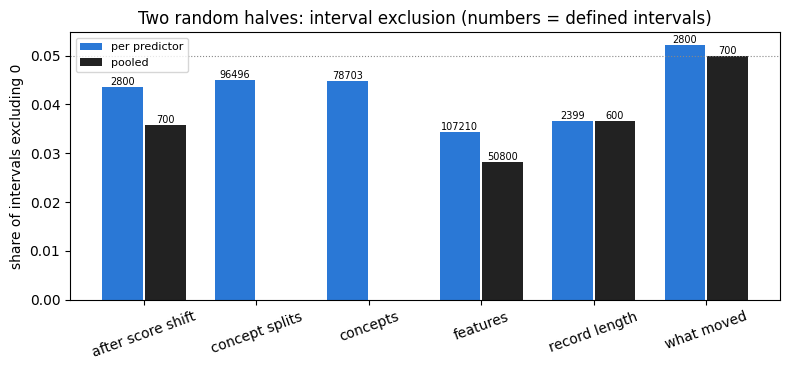

In [22]:
fig, ax = plt.subplots(figsize=(8, 3.8))
order = list(exclusion['level'].unique())
for k, (rows_kind, color) in enumerate((('per predictor', '#2a78d6'), ('pooled', '#222222'))):
    t = exclusion[exclusion['rows'] == rows_kind].set_index('level').reindex(order)
    x = np.arange(len(order)) + (k - .5) * .38
    ax.bar(x, t['share_excluding_zero'], width=.36, color=color, label=rows_kind)
    for xi, (share, n) in zip(x, zip(t['share_excluding_zero'], t['defined'])):
        if np.isfinite(share):
            ax.annotate(f'{int(n)}', (xi, share), ha='center', va='bottom', fontsize=7)
ax.axhline(.05, color='#888888', lw=.8, ls=':')
ax.set_xticks(np.arange(len(order)), order, rotation=20)
ax.set(ylabel='share of intervals excluding 0', title='Two random halves: interval exclusion (numbers = defined intervals)')
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUTPUT / 'figure_6_no_change_interval_exclusion.png', dpi=130); plt.show()

## What the profile reported, plant × level (pooled over the four predictors)

Concept columns use rule membership (the profile's quantity). Empty cells: not computed for that plant (e.g. flips without the feature exist only for recording stops).

In [23]:
def cell(level, measure, item=''):
    t = compared.query("predictor == @SUMMARY and level == @level and measure == @measure and item == @item").set_index(['plant', 'dose'])
    return fmt(t).reindex(labels)

closing = pd.DataFrame({label: cell(level, measure) for label, (table, level, measure) in HEADLINE.items()})
band = headline.query("level == 'what moved' and measure == 'false_alarm_rate' and predictor == @SUMMARY").iloc[0]
closing.insert(0, 'scale reference, not the no-change value for a paired plant (exactly 0): false-alarm change between two random halves of different patients, 2.5-97.5%',
               f"[{band['random_halves_low']:+.4f}, {band['random_halves_high']:+.4f}]")
stopped = feature_ranks[feature_ranks['predictor'] == SUMMARY].pivot_table(index=['plant', 'shift'], columns='view', values='rank_by_size', aggfunc='first')
for view in ('all', 'same_outcome_deaths', 'same_outcome_survivors'):
    closing[f'stopped feature rank: {view}'] = stopped[view].reindex(labels).to_numpy() if view in stopped else np.nan
concepts_all = pd.concat([collect(p, 'concepts') for p in ('P1', 'P2', 'P3', 'P4')], ignore_index=True)
for side, rate in (('survivors', 'false-alarm'), ('deaths', 'missed-death')):
    for version, text in (('observed', 'raw'), ('observed_minus_score_alone', 'minus score-alone')):
        part = concepts_all[concepts_all['measure'] == f'rule|inside|{side}|{version}']
        closing[f'concepts: largest |inside {rate} change|, {text}'] = part.assign(size=part['value'].abs()).groupby(['plant', 'dose'])['size'].max().reindex(labels).to_numpy()
pooled_ranks = concept_rank_table[concept_rank_table['predictor'] == 'pooled'].set_index(['shift', 'measure'])
for side in ('survivors', 'deaths'):
    for version in ('observed', 'observed_minus_score_alone'):
        key = f'rule|inside|{side}|{version}'
        closing[f'pooled ranks of rule-using concepts ({side}, {version})'] = [pooled_ranks.loc[(d, key), 'ranks_of_concepts_using_feature'] if (d, key) in pooled_ranks.index else '' for p, d in labels]
        closing[f'best pooled rank of other concepts ({side}, {version})'] = [pooled_ranks.loc[(d, key), 'best_rank_of_other_concepts'] if (d, key) in pooled_ranks.index else np.nan for p, d in labels]
flip_sum = flip_table.groupby(['plant', 'dose']).sum(numeric_only=True, min_count=1)  # not computed -> empty, not 0
for name in ('survivors_no_longer_flagged', 'survivors_newly_flagged', 'deaths_no_longer_flagged', 'deaths_newly_flagged', 'flips_without_feature'):
    closing[f'patients: {name.replace("_", " ")}'] = flip_sum[name].reindex(labels).to_numpy() if name in flip_sum else np.nan
closing['max score change without the feature'] = flip_table.groupby(['plant', 'dose'])['max_score_change_without_feature'].max().reindex(labels).to_numpy() if 'max_score_change_without_feature' in flip_table else np.nan
closing.to_csv(OUTPUT / 'closing_table.csv')
with pd.option_context('display.max_columns', 60, 'display.max_colwidth', 40):
    display(closing.T)

plant                                                             P1  \
dose                                                            0.5x   
scale reference, not the no-change va...          [-0.0430, +0.0431]   
false-alarm rate change                   +0.0353 [+0.0246, +0.0467]   
false-alarm change after score shift      +0.0000 [+0.0000, +0.0000]   
recall change                             +0.0171 [+0.0000, +0.0444]   
recall change after score shift           +0.0000 [+0.0000, +0.0000]   
survivors: mix (record length)            +0.0000 [+0.0000, +0.0000]   
survivors: within equal length            +0.0353 [+0.0246, +0.0467]   
deaths: mix (record length)               +0.0000 [+0.0000, +0.0000]   
deaths: within equal length               -0.0171 [-0.0444, +0.0000]   
stopped feature rank: all                                        NaN   
stopped feature rank: same_outcome_de...                         NaN   
stopped feature rank: same_outcome_su...                         NaN   
concepts: largest |inside false-alarm...                    0.285714   
concepts: largest |inside false-alarm...                    0.107113   
concepts: largest |inside missed-deat...                    0.166667   
concepts: largest |inside missed-deat...                    0.266734   
pooled ranks of rule-using concepts (...                               
best pooled rank of other concepts (s...                         NaN   
pooled ranks of rule-using concepts (...                               
best pooled rank of other concepts (s...                         NaN   
pooled ranks of rule-using concepts (...                               
best pooled rank of other concepts (d...                         NaN   
pooled ranks of rule-using concepts (...                               
best pooled rank of other concepts (d...                         NaN   
patients: survivors no longer flagged                            0.0   
patients: survivors newly flagged                               41.0   
patients: deaths no longer flagged                               0.0   
patients: deaths newly flagged                                   2.0   
patients: flips without feature                                  NaN   
max score change without the feature                             NaN   

plant                                                                 \
dose                                                              1x   
scale reference, not the no-change va...          [-0.0430, +0.0431]   
false-alarm rate change                   +0.0594 [+0.0464, +0.0731]   
false-alarm change after score shift      +0.0000 [+0.0000, +0.0000]   
recall change                             +0.0171 [+0.0000, +0.0444]   
recall change after score shift           +0.0000 [+0.0000, +0.0000]   
survivors: mix (record length)            +0.0000 [+0.0000, +0.0000]   
survivors: within equal length            +0.0594 [+0.0464, +0.0731]   
deaths: mix (record length)               +0.0000 [+0.0000, +0.0000]   
deaths: within equal length               -0.0171 [-0.0444, +0.0000]   
stopped feature rank: all                                        NaN   
stopped feature rank: same_outcome_de...                         NaN   
stopped feature rank: same_outcome_su...                         NaN   
concepts: largest |inside false-alarm...                    0.454545   
concepts: largest |inside false-alarm...                    0.107113   
concepts: largest |inside missed-deat...                    0.166667   
concepts: largest |inside missed-deat...                    0.408775   
pooled ranks of rule-using concepts (...                               
best pooled rank of other concepts (s...                         NaN   
pooled ranks of rule-using concepts (...                               
best pooled rank of other concepts (s...                         NaN   
pooled ranks of rule-using concepts (...                               
best pooled rank of other concepts (d..

In [24]:
for name in ('what_moved', 'record_length', 'concepts'):
    pd.concat([r[name] for r in results.values()], ignore_index=True).to_csv(OUTPUT / f'plant_{name}.csv', index=False)
for name in ('features', 'concept_splits', 'concept_error_rates'):
    pd.concat([r[name] for r in results.values()], ignore_index=True).to_csv(OUTPUT / f'plant_{name}.csv.gz', index=False)
manifest = dict(started_utc=started_utc, elapsed_seconds=time.perf_counter() - started, section_seconds=timings, dry_run=DRY_RUN,
                references=list(REFERENCES), rows_per_predictor={str(r): int(len(before[r]['frame'])) for r in cases},
                deaths_per_predictor={str(r): int(before[r]['frame']['label'].sum()) for r in cases},
                bootstrap_patients=int(len(bootstrap[0])), bootstrap_draws=DRAWS, bootstrap_seed=SEED,
                no_change_splits=NO_CHANGE_SPLITS, no_change_bootstrap_splits=NO_CHANGE_BOOTSTRAP_SPLITS,
                no_change_split_seeds='numpy default_rng([split, predictor position]), split = 1..no_change_splits',
                p1_offsets={str(k): v for k, v in offset.items()}, p1_multipliers=DOSE_MULTIPLIERS, p2_month_drops=MONTH_DROPS,
                tolerances=TOLERANCES, workers=WORKERS, load_seconds=study['load_seconds'], python=platform.python_version(),
                thread_env={k: os.environ.get(k) for k in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'CUDA_VISIBLE_DEVICES')},
                source_sha256={n: hashlib.sha256(Path(n).read_bytes()).hexdigest() for n in ('error_profiles.py', 'error_profile_checks.py', 'error_profile_checks.ipynb')})
(OUTPUT / 'run_manifest.json').write_text(json.dumps(manifest, indent=2, default=str))
print(json.dumps({k: manifest[k] for k in ('elapsed_seconds', 'section_seconds')}, indent=2))

{
  "elapsed_seconds": 2633.944055587024,
  "section_seconds": {
    "load and alignment": 15.140795665996848,
    "P5 point splits": 339.0802836419898,
    "P5 bootstrap splits": 1546.6658361130103,
    "P1": 217.57601935000275,
    "P2": 213.53045390400803,
    "P3 and P4": 286.13876175301266
  }
}
